In [1]:
import sys

print(sys.executable)

/mnt/home/plazarod/.conda/envs/xenium_spatial/bin/python


In [6]:
import argparse
import numpy as np
import anndata as ad
from scipy import sparse
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf
import scanpy as sc
import zarr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

In [3]:
import pandas as pd
from pandas._config.config import register_option
from pandas._config.config import OptionError

try:
    pd.get_option("future.infer_string")
except OptionError:
    register_option(
        "future.infer_string",
        False,
        doc="Compatibility option required by newer anndata."
    )

# Part1 : H&E Xenium overlay

In [1]:
import tifffile

base = "/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/Xenium_test"

dapi_path = f"{base}/morphology_focus/ch0000_dapi.ome.tif"
he_path = f"{base}/post_xenium_HE.ome.tif"

for name, path in [("DAPI", dapi_path), ("H&E", he_path)]:
    with tifffile.TiffFile(path) as tif:
        series = tif.series[0]
        print(f"\n{name}")
        print("Axes:", series.axes)
        print("Full resolution:", series.shape)
        print("Pyramid levels:")
        for i, level in enumerate(series.levels):
            print(i, level.shape)


DAPI
Axes: CYX
Full resolution: (35, 27328, 54002)
Pyramid levels:
0 (35, 27328, 54002)
1 (35, 13664, 27001)
2 (35, 6832, 13500)
3 (35, 3416, 6750)
4 (35, 1708, 3375)
5 (35, 854, 1687)
6 (35, 427, 843)
7 (35, 213, 421)

H&E
Axes: YXS
Full resolution: (60680, 24096, 3)
Pyramid levels:
0 (60680, 24096, 3)
1 (30340, 12048, 3)
2 (15170, 6024, 3)
3 (7585, 3012, 3)
4 (3793, 1506, 3)
5 (1897, 753, 3)
6 (949, 377, 3)


In [2]:


def load_preview(path, target_size=2000):
    with tifffile.TiffFile(path) as tif:
        levels = tif.series[0].levels
        sizes = [
            max(level.shape[-2:])
            for level in levels
        ]

        candidates = [
            i for i, size in enumerate(sizes)
            if size <= target_size
        ]

        level_idx = candidates[0] if candidates else len(levels) - 1
        img = levels[level_idx].asarray()

        return img, level_idx, levels[0].shape, levels[level_idx].shape

dapi, dapi_level, dapi_full, dapi_small = load_preview(dapi_path)
he, he_level, he_full, he_small = load_preview(he_path)

print("DAPI:", dapi.shape, "level:", dapi_level)
print("H&E:", he.shape, "level:", he_level)

DAPI: (35, 854, 1687) level: 5
H&E: (3793, 1506, 3) level: 4


DAPI shape: (854, 1687)


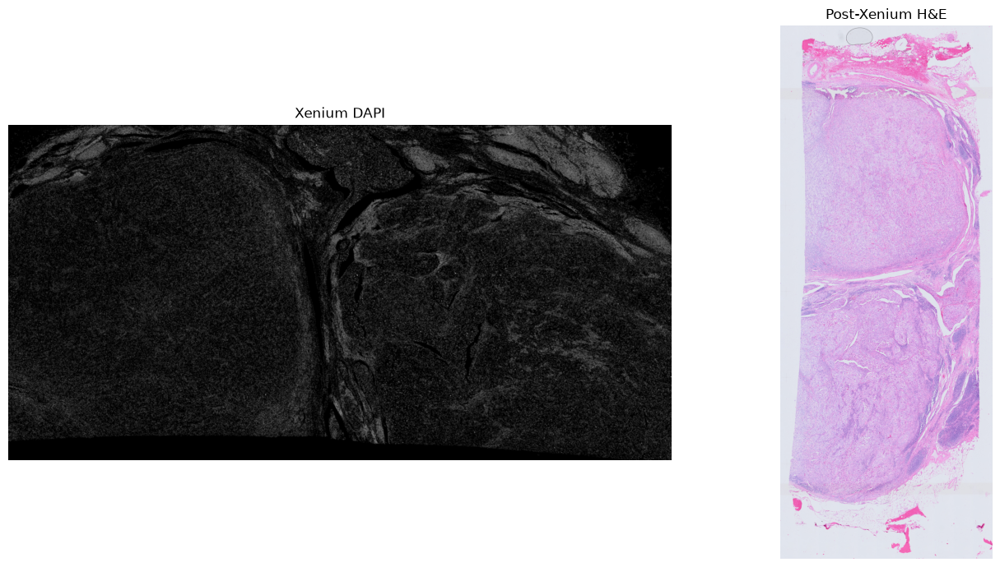

In [9]:
dapi_2d = dapi[0, :, :]

print("DAPI shape:", dapi_2d.shape)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(dapi_2d, cmap="gray")
axes[0].set_title("Xenium DAPI")

axes[1].imshow(np.squeeze(he))
axes[1].set_title("Post-Xenium H&E")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
print("DAPI:", dapi.shape)
print("H&E:", he.shape)

DAPI: (35, 854, 1687)
H&E: (3793, 1506, 3)


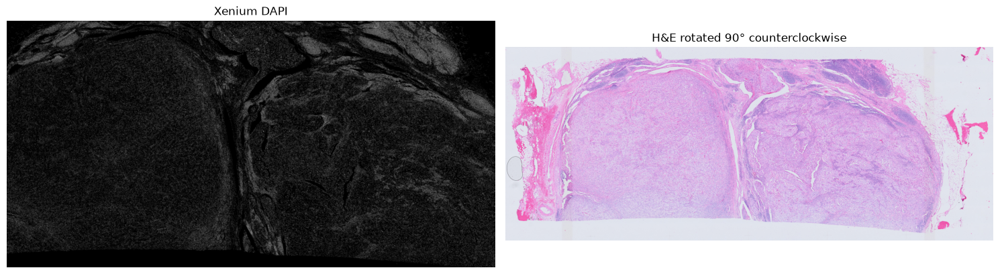

In [11]:
# Rotate H&E 90 degrees counterclockwise
he_rotated = np.rot90(he, k=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].imshow(dapi_2d, cmap="gray")
axes[0].set_title("Xenium DAPI")

axes[1].imshow(he_rotated)
axes[1].set_title("H&E rotated 90° counterclockwise")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
! pip install opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 82.3 MB/s  0:00:006m0:00:0100:01


In [17]:
### Identify matching features
import cv2


def to_uint8(img):
    img = np.asarray(img)

    if img.ndim == 3:
        img = cv2.cvtColor(img[:, :, :3], cv2.COLOR_RGB2GRAY)

    img = img.astype(np.float32)
    lo, hi = np.percentile(img, [1, 99.5])

    return ((np.clip(img, lo, hi) - lo) /
            max(hi - lo, 1e-6) * 255).astype(np.uint8)

# Convert H&E to grayscale
he_gray = to_uint8(he_rotated)
dapi_gray = to_uint8(dapi_2d)

# Enhance local contrast
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
he_gray = clahe.apply(he_gray)
dapi_gray = clahe.apply(dapi_gray)

# Detect features
sift = cv2.SIFT_create(nfeatures=10000)

kp_he, des_he = sift.detectAndCompute(he_gray, None)
kp_dapi, des_dapi = sift.detectAndCompute(dapi_gray, None)

print("H&E features:", len(kp_he))
print("DAPI features:", len(kp_dapi))

H&E features: 10000
DAPI features: 10000


In [20]:
! pip install SimpleITK

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 74.2 MB/s  0:00:006m0:00:0100:01


In [21]:
import SimpleITK as sitk
import numpy as np
## match features and estimate alignment
# Use grayscale previews
fixed = sitk.GetImageFromArray(dapi_gray.astype(np.float32))
moving = sitk.GetImageFromArray(he_gray.astype(np.float32))

# Normalize image intensities
fixed = sitk.Normalize(fixed)
moving = sitk.Normalize(moving)

# Initialize a centered affine transformation
initial = sitk.CenteredTransformInitializer(
    fixed,
    moving,
    sitk.Euler2DTransform(),
    sitk.CenteredTransformInitializerFilter.GEOMETRY
)

registration = sitk.ImageRegistrationMethod()

# Mutual information works across different imaging modalities
registration.SetMetricAsMattesMutualInformation(
    numberOfHistogramBins=50
)

registration.SetMetricSamplingStrategy(registration.RANDOM)
registration.SetMetricSamplingPercentage(0.1)

registration.SetInterpolator(sitk.sitkLinear)

registration.SetOptimizerAsRegularStepGradientDescent(
    learningRate=1.0,
    minStep=0.001,
    numberOfIterations=200
)

registration.SetOptimizerScalesFromPhysicalShift()

registration.SetInitialTransform(initial, inPlace=False)

final_transform = registration.Execute(fixed, moving)

print("Registration metric:", registration.GetMetricValue())
print("Optimizer stop:", registration.GetOptimizerStopConditionDescription())

Registration metric: -0.004864957070715476
Optimizer stop: RegularStepGradientDescentOptimizerv4: Gradient magnitude tolerance met after 11 iterations. Gradient magnitude (8.77523e-05) is less than gradient magnitude tolerance (0.0001).


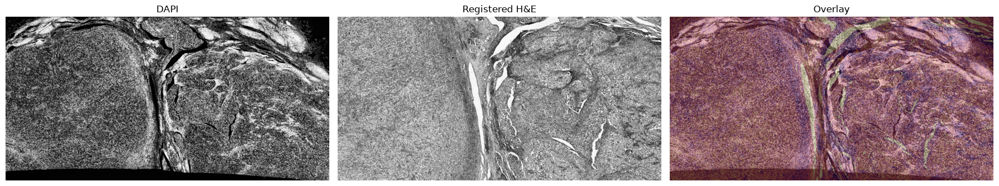

In [22]:
## Visualize the overlay
aligned = sitk.Resample(
    moving,
    fixed,
    final_transform,
    sitk.sitkLinear,
    0.0
)

aligned_array = sitk.GetArrayFromImage(aligned)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(dapi_gray, cmap="gray")
axes[0].set_title("DAPI")

axes[1].imshow(aligned_array, cmap="gray")
axes[1].set_title("Registered H&E")

axes[2].imshow(dapi_gray, cmap="gray")
axes[2].imshow(aligned_array, cmap="magma", alpha=0.4)
axes[2].set_title("Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
##Export the H&E alignment matrix

from pathlib import Path
import SimpleITK as sitk

outdir = Path(
    "/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/Xenium_test"
)

# Transform from H&E preview pixels to DAPI preview pixels
forward = final_transform.GetInverse()

# Convert the SimpleITK transform into a 3x3 homogeneous matrix
p0 = np.array(forward.TransformPoint((0.0, 0.0)))
px = np.array(forward.TransformPoint((1.0, 0.0)))
py = np.array(forward.TransformPoint((0.0, 1.0)))

M_preview = np.eye(3)
M_preview[:2, 0] = px - p0
M_preview[:2, 1] = py - p0
M_preview[:2, 2] = p0

pd.DataFrame(M_preview).to_csv(
    outdir / "HE_to_DAPI_preview_transform.csv",
    index=False,
    header=False
)

print("H&E → DAPI preview transform:")
print(M_preview)

H&E → DAPI preview transform:
[[ 9.99999992e-01  1.24428930e-04 -1.05368608e+03]
 [-1.24428930e-04  9.99999992e-01 -3.24321521e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [24]:
## Export full resoluton transform
# Original full-resolution and preview dimensions
he_full_h, he_full_w = he_full[-2:]
he_prev_h, he_prev_w = he.shape[:2]

dapi_full_h, dapi_full_w = dapi_full[-2:]
dapi_prev_h, dapi_prev_w = dapi_2d.shape

# Full-resolution H&E -> original H&E preview
S_he = np.diag([
    he_prev_w / he_full_w,
    he_prev_h / he_full_h,
    1.0
])

# Original H&E preview -> 90-degree CCW rotated preview
R_he = np.array([
    [0, 1, 0],
    [-1, 0, he_prev_w - 1],
    [0, 0, 1]
], dtype=float)

# DAPI preview -> full-resolution DAPI
S_dapi_inv = np.diag([
    dapi_full_w / dapi_prev_w,
    dapi_full_h / dapi_prev_h,
    1.0
])

M_full = S_dapi_inv @ M_preview @ R_he @ S_he

pd.DataFrame(M_full).to_csv(
    outdir / "HE_to_DAPI_full_resolution_transform.csv",
    index=False,
    header=False
)

print("Full-resolution H&E → DAPI transform:")
print(M_full)

Full-resolution H&E → DAPI transform:
[[-1.99949281e+00  5.03886412e+00 -3.37232028e+04]
 [-1.60639999e+04 -6.26771491e-04  3.77817109e+04]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


## Quick check of registration accuracy

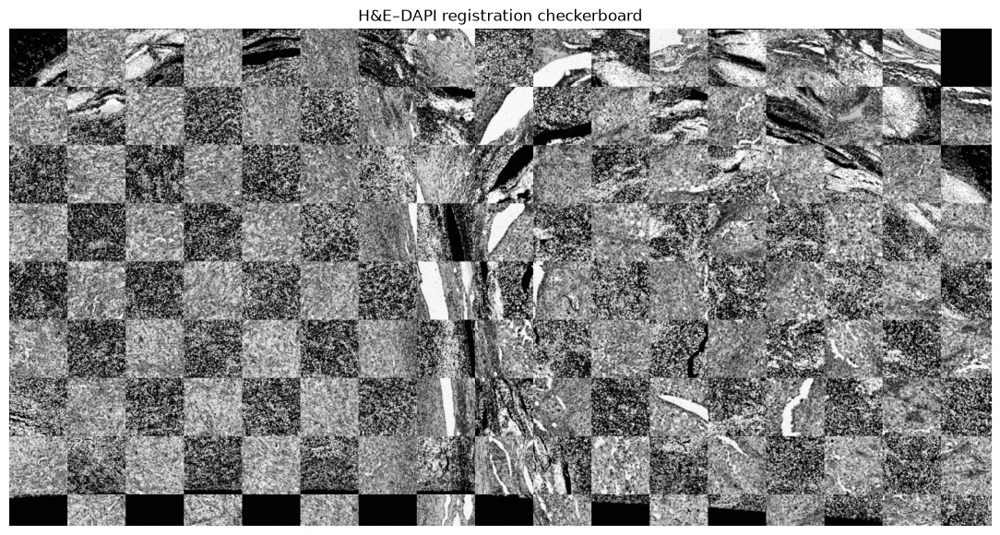

In [25]:

# Normalize both registered grayscale previews
def normalize(img):
    return cv2.normalize(
        img.astype(np.float32),
        None, 0, 1,
        cv2.NORM_MINMAX
    )

fixed = normalize(dapi_gray)
moving = normalize(aligned_array)

h, w = fixed.shape
yy, xx = np.indices((h, w))

checker_mask = ((xx // 100 + yy // 100) % 2) == 0
checkerboard = np.where(checker_mask, fixed, moving)

plt.figure(figsize=(14, 7))
plt.imshow(checkerboard, cmap="gray")
plt.title("H&E–DAPI registration checkerboard")
plt.axis("off")
plt.savefig(outdir / "HE_DAPI_checkerboard.png",
            dpi=200, bbox_inches="tight")
plt.show()

In [26]:
#Quantify registration accuracy
from scipy.ndimage import binary_fill_holes

# Create approximate tissue masks
dapi_mask = fixed > 0.12

# H&E grayscale is typically darker in tissue regions
# than in the white background.
he_mask = moving < 0.85

# Exclude very small isolated regions
from skimage.morphology import remove_small_objects

dapi_mask = remove_small_objects(
    binary_fill_holes(dapi_mask), min_size=500
)

he_mask = remove_small_objects(
    binary_fill_holes(he_mask), min_size=500
)

intersection = np.logical_and(dapi_mask, he_mask).sum()

dice = (
    2 * intersection /
    (dapi_mask.sum() + he_mask.sum())
)

print(f"Tissue overlap Dice coefficient: {dice:.3f}")

Tissue overlap Dice coefficient: 0.952


/tmp/ipykernel_2290913/3096065441.py:14: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  dapi_mask = remove_small_objects(
/tmp/ipykernel_2290913/3096065441.py:18: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  he_mask = remove_small_objects(


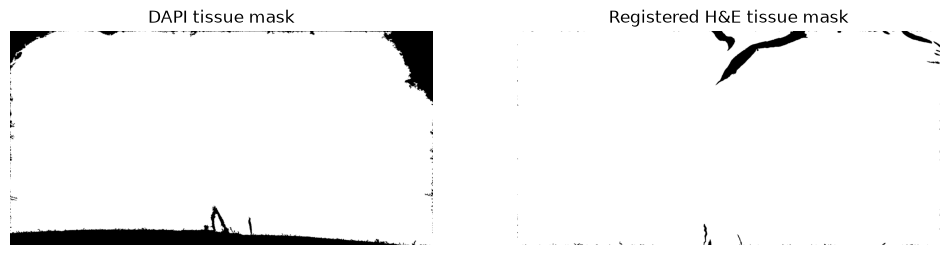

In [27]:
## Plot the masks
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(dapi_mask, cmap="gray")
axes[0].set_title("DAPI tissue mask")

axes[1].imshow(he_mask, cmap="gray")
axes[1].set_title("Registered H&E tissue mask")

for ax in axes:
    ax.axis("off")

plt.show()

### The H&E image was registered to the Xenium DAPI morphology image using an initial 90° rotation followed by mutual-information-based rigid registration in SimpleITK. Visual assessment using blended overlays and checkerboard comparisons demonstrated approximate alignment of the major tissue regions and central anatomical structures. Local discrepancies remained, particularly around tissue boundaries and internal fissures. Although the initial tissue-mask Dice coefficient was 0.952, the masks included large contiguous tissue regions and therefore did not provide a reliable measure of local registration accuracy.

# Load data and QC

In [6]:

from pathlib import Path

path = Path(
    "/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/Xenium_test"
)

adata = sc.read_10x_h5(
    path / "cell_feature_matrix.h5",
    gex_only=True
)

adata.var_names_make_unique()

print(adata)

AnnData object with n_obs × n_vars = 465534 × 405
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)


In [7]:
##inspect the data
adata.layers["counts"] = adata.X.copy()
print(adata.shape)
print(adata.obs.head())
print(adata.var.head())


(465534, 405)
Empty DataFrame
Columns: []
Index: [aaaaaglh-1, aaaadpem-1, aaaafdfe-1, aaaagljm-1, aaaahdcb-1]
               gene_ids    feature_types   genome
ABCC11  ENSG00000121270  Gene Expression  Unknown
ACE2    ENSG00000130234  Gene Expression  Unknown
ACKR1   ENSG00000213088  Gene Expression  Unknown
ACTA2   ENSG00000107796  Gene Expression  Unknown
ACTG2   ENSG00000163017  Gene Expression  Unknown


In [8]:
#load cell-level metadata
path = "/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/Xenium_test/"

cells = pd.read_parquet(path + "cells.parquet")

print(cells.shape)
print(cells.columns.tolist())
print(cells.head())

(465534, 14)
['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method']
      cell_id  x_centroid   y_centroid  transcript_counts  \
0  aaaaaglh-1  374.758087  2626.659668                 75   
1  aaaadpem-1  409.842133  2682.607666                 71   
2  aaaafdfe-1  378.044220  2686.810059                 96   
3  aaaagljm-1  389.725861  2853.164307                154   
4  aaaahdcb-1  397.266266  2866.572021                 28   

   control_probe_counts  genomic_control_counts  control_codeword_counts  \
0                     0                       0                        0   
1                     0                       0                        0   
2                     0                       0                        0   
3                     0          

In [9]:
##Verify metadata matches
cells = cells.set_index("cell_id")

print("AnnData cells:", adata.n_obs)
print("Metadata cells:", len(cells))
print("Matching cell IDs:", adata.obs_names.isin(cells.index).sum())

AnnData cells: 465534
Metadata cells: 465534
Matching cell IDs: 465534


In [10]:
#merge counts and metadata
adata.obs = cells.reindex(adata.obs_names).copy()

In [11]:
adata.var

,gene_ids,feature_types,genome
ABCC11,ENSG00000121270,Gene Expression,Unknown
ACE2,ENSG00000130234,Gene Expression,Unknown
ACKR1,ENSG00000213088,Gene Expression,Unknown
ACTA2,ENSG00000107796,Gene Expression,Unknown
ACTG2,ENSG00000163017,Gene Expression,Unknown
...,...,...,...
VIM,ENSG00000026025,Gene Expression,Unknown
VSIG4,ENSG00000155659,Gene Expression,Unknown
VSIR,ENSG00000107738,Gene Expression,Unknown
VWA5A,ENSG00000110002,Gene Expression,Unknown


In [12]:
#export
adata.write_h5ad("/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/Xenium_test/Xenium_RCC_raw_RNA.h5ad")

# Calculate Cell-level QC metrics

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Work with unnormalized RNA counts
adata.X = adata.layers["counts"].copy()

sc.pp.calculate_qc_metrics(
    adata,
    percent_top=None,
    log1p=False,
    inplace=True
)

print(adata.obs[
    ["total_counts", "n_genes_by_counts"]
].describe())

        total_counts  n_genes_by_counts
count  465534.000000      465534.000000
mean      106.099541          35.386685
std       124.662567          20.429703
min         0.000000           0.000000
25%        40.000000          21.000000
50%        70.000000          32.000000
75%       124.000000          45.000000
max      2999.000000         216.000000


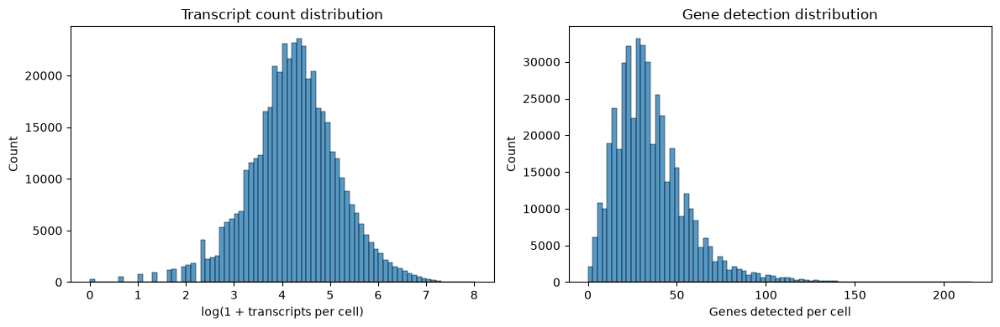

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    np.log1p(adata.obs["total_counts"]),
    bins=80,
    ax=axes[0]
)
axes[0].set_xlabel("log(1 + transcripts per cell)")
axes[0].set_title("Transcript count distribution")

sns.histplot(
    adata.obs["n_genes_by_counts"],
    bins=80,
    ax=axes[1]
)
axes[1].set_xlabel("Genes detected per cell")
axes[1].set_title("Gene detection distribution")

plt.tight_layout()
plt.show()

In [15]:
print(f"Average transcripts per cell: {adata.obs['total_counts'].mean():,.2f}")
print(f"Total cells: {adata.n_obs:,}")

print(f"Mean transcripts per cell: "
      f"{adata.obs['total_counts'].mean():,.2f}")

print(f"Median transcripts per cell: "
      f"{adata.obs['total_counts'].median():,.2f}")

print(f"Mean genes detected per cell: "
      f"{adata.obs['n_genes_by_counts'].mean():,.2f}")

print(f"Median genes detected per cell: "
      f"{adata.obs['n_genes_by_counts'].median():,.2f}")

Average transcripts per cell: 106.10
Total cells: 465,534
Mean transcripts per cell: 106.10
Median transcripts per cell: 70.00
Mean genes detected per cell: 35.39
Median genes detected per cell: 32.00


In [16]:
##Extract and store x,y coor
adata.obsm["spatial"] = adata.obs[
    ["x_centroid", "y_centroid"]
].to_numpy()

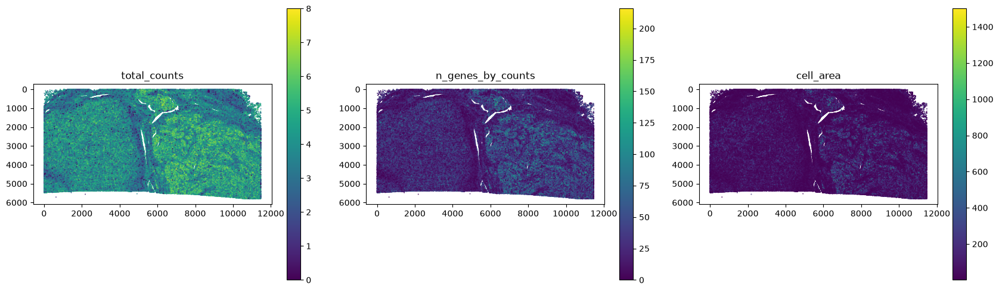

In [17]:
##visualize spatial QC
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    "total_counts",
    "n_genes_by_counts",
    "cell_area"
]

for ax, metric in zip(axes, metrics):

    values = adata.obs[metric].to_numpy()

    if metric == "total_counts":
        values = np.log1p(values)

    scatter = ax.scatter(
        adata.obsm["spatial"][:, 0],
        adata.obsm["spatial"][:, 1],
        c=values,
        s=0.15,
        cmap="viridis",
        rasterized=True
    )

    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.set_title(metric)
    plt.colorbar(scatter, ax=ax)

plt.tight_layout()
plt.show()

# Calculate Transcript-Level QC metrics

In [18]:
import pyarrow.parquet as pq

transcript_file = path + "/transcripts.parquet"

pf = pq.ParquetFile(transcript_file)

print("Number of transcripts:", pf.metadata.num_rows)
print("Available columns:")
print(pf.schema.names)

Number of transcripts: 77056936
Available columns:
['transcript_id', 'cell_id', 'overlaps_nucleus', 'feature_name', 'x_location', 'y_location', 'z_location', 'qv', 'fov_name', 'nucleus_distance', 'codeword_index', 'codeword_category', 'is_gene']


Fraction passing Q20: 0.817006142055791


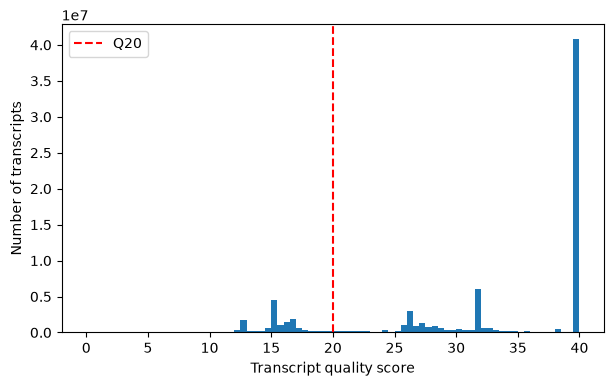

In [19]:
qv_values = []

for batch in pf.iter_batches(
    columns=["qv"],
    batch_size=500_000
):
    qv_values.append(batch.column("qv").to_numpy())

qv = np.concatenate(qv_values)

print("Fraction passing Q20:", np.mean(qv >= 20))

plt.figure(figsize=(7, 4))
plt.hist(qv, bins=80)
plt.axvline(20, color="red", linestyle="--", label="Q20")
plt.xlabel("Transcript quality score")
plt.ylabel("Number of transcripts")
plt.legend()
plt.show()

Total records with valid QV: 77,056,936
Fraction QV ≥ 20: 81.70%
Fraction QV ≥ 30: 66.94%


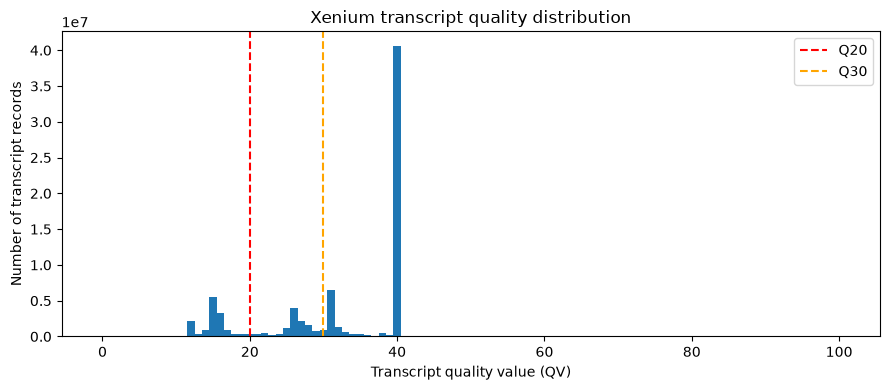

In [20]:


qv_hist = np.zeros(101, dtype=np.int64)
total_transcripts = 0
passing_q20 = 0
passing_q30 = 0

for batch in pf.iter_batches(
    columns=["qv"],
    batch_size=500_000
):
    qv = batch.column("qv").to_numpy()
    qv = qv[np.isfinite(qv)]

    total_transcripts += len(qv)
    passing_q20 += np.sum(qv >= 20)
    passing_q30 += np.sum(qv >= 30)

    hist, _ = np.histogram(
        np.clip(qv, 0, 100),
        bins=np.arange(102)
    )
    qv_hist += hist

print(f"Total records with valid QV: {total_transcripts:,}")
print(f"Fraction QV ≥ 20: {passing_q20 / total_transcripts:.2%}")
print(f"Fraction QV ≥ 30: {passing_q30 / total_transcripts:.2%}")

plt.figure(figsize=(9, 4))
plt.bar(np.arange(101), qv_hist, width=1)
plt.axvline(20, color="red", linestyle="--", label="Q20")
plt.axvline(30, color="orange", linestyle="--", label="Q30")
plt.xlabel("Transcript quality value (QV)")
plt.ylabel("Number of transcript records")
plt.title("Xenium transcript quality distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
from collections import Counter

categories = Counter()

for batch in pf.iter_batches(
    columns=["codeword_category"],
    batch_size=500_000
):
    categories.update(
        batch.column("codeword_category").to_pylist()
    )

print("Transcript categories:")
for category, count in categories.most_common():
    print(f"{category}: {count:,}")

Transcript categories:
predesigned_gene: 40,106,944
custom_gene: 36,850,266
negative_control_codeword: 39,963
unassigned_codeword: 23,779
negative_control_probe: 20,874
deprecated_codeword: 15,110



Q20+ transcripts by category:
predesigned_gene: 33,063,509
custom_gene: 29,884,928
negative_control_codeword: 2,566
negative_control_probe: 2,461
unassigned_codeword: 1,361
deprecated_codeword: 1,165


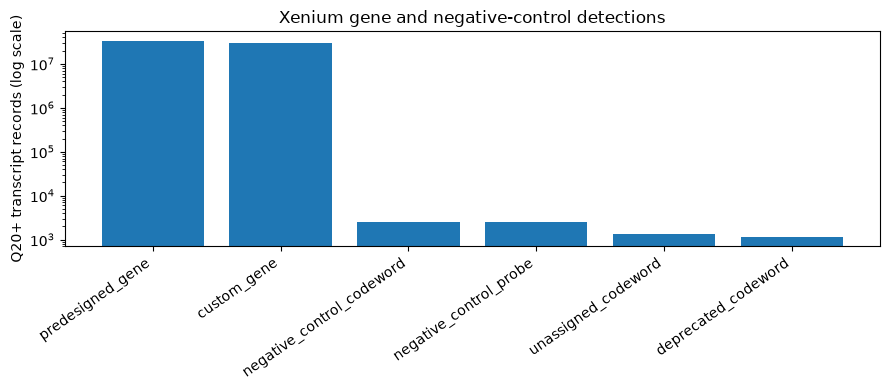

In [22]:
category_qc = Counter()

for batch in pf.iter_batches(
    columns=["codeword_category", "qv"],
    batch_size=500_000
):
    df = batch.to_pandas()
    df = df[df["qv"] >= 20]

    category_qc.update(
        df["codeword_category"].value_counts().to_dict()
    )

print("\nQ20+ transcripts by category:")

for category, count in category_qc.most_common():
    print(f"{category}: {count:,}")

control_df = pd.DataFrame(
    category_qc.items(),
    columns=["Category", "Count"]
).sort_values("Count", ascending=False)

plt.figure(figsize=(9, 4))
plt.bar(control_df["Category"], control_df["Count"])
plt.yscale("log")
plt.ylabel("Q20+ transcript records (log scale)")
plt.title("Xenium gene and negative-control detections")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [23]:
##calcuate relative fractions passing Q20
gene_categories = ["predesigned_gene", "custom_gene"]
control_categories = [
    "negative_control_codeword",
    "negative_control_probe"
]

qc_summary = pd.DataFrame({
    "Total": pd.Series(categories),
    "Q20_pass": pd.Series(category_qc)
}).fillna(0)

qc_summary["Q20_fraction"] = (
    qc_summary["Q20_pass"] / qc_summary["Total"]
)

print(qc_summary)

                              Total  Q20_pass  Q20_fraction
custom_gene                36850266  29884928      0.810983
deprecated_codeword           15110      1165      0.077101
negative_control_codeword     39963      2566      0.064209
negative_control_probe        20874      2461      0.117898
predesigned_gene           40106944  33063509      0.824384
unassigned_codeword           23779      1361      0.057235


# Transcript to cell assignment QC

In [24]:
import pyarrow.parquet as pq

pf = pq.ParquetFile(path+"/transcripts.parquet")

batch = next(
    pf.iter_batches(
        columns=["cell_id", "qv", "codeword_category"],
        batch_size=100_000
    )
)

print(batch.to_pandas()["cell_id"].value_counts(
    dropna=False
).head(10))

print(batch.schema)

cell_id
UNASSIGNED    30118
hfmcanhi-1      296
fkipjdia-1      277
aegfhlhl-1      276
aeehbhbg-1      266
admjmabo-1      262
aegnlael-1      262
hgphlech-1      240
fjliifbn-1      231
hgpgipac-1      225
Name: count, dtype: int64
cell_id: large_string
qv: float
codeword_category: large_string


In [25]:
import pyarrow.compute as pc
import pyarrow as pa


pf = pq.ParquetFile(path+"/transcripts.parquet")

assigned = 0
total = 0

for batch in pf.iter_batches(
    columns=["cell_id", "qv", "codeword_category"],
    batch_size=500_000
):
    category = batch.column("codeword_category")
    qv = batch.column("qv")
    cell_id = batch.column("cell_id")

    # Q20+ gene transcripts
    gene_mask = pc.and_(
        pc.greater_equal(qv, 20),
        pc.is_in(
            category,
            value_set=pa.array([
                "predesigned_gene",
                "custom_gene"
            ])
        )
    )

    # Valid cell assignments
    valid_cell = pc.and_(
        pc.is_valid(cell_id),
        pc.and_(
            pc.not_equal(cell_id, ""),
            pc.not_equal(cell_id, "UNASSIGNED")
        )
    )

    assigned += pc.sum(
        pc.and_(gene_mask, valid_cell)
    ).as_py() or 0

    total += pc.sum(gene_mask).as_py() or 0

unassigned = total - assigned

print(f"Assigned: {assigned:,}")
print(f"Unassigned: {unassigned:,}")
print(f"Total Q20+ gene transcripts: {total:,}")
print(f"Assignment rate: {assigned / total:.2%}")

Assigned: 49,392,945
Unassigned: 13,555,492
Total Q20+ gene transcripts: 62,948,437
Assignment rate: 78.47%


# Spatial Distribution of low-quality transcripts

In [26]:
samples = []
rng = np.random.default_rng(42)

for batch in pf.iter_batches(
    columns=["x_location", "y_location", "qv"],
    batch_size=500_000
):
    df = batch.to_pandas()

    # Sample approximately 1% from each batch
    keep = rng.random(len(df)) < 0.01
    samples.append(df.loc[keep])

transcript_sample = pd.concat(samples, ignore_index=True)

print(f"Sampled transcripts: {len(transcript_sample):,}")

Sampled transcripts: 770,811


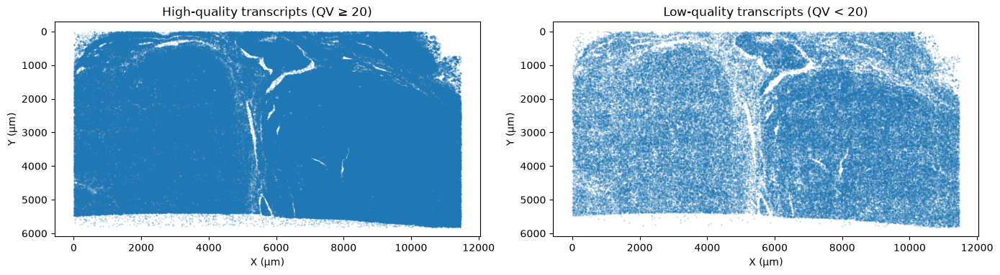

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, mask, title in zip(
    axes,
    [
        transcript_sample["qv"] >= 20,
        transcript_sample["qv"] < 20
    ],
    [
        "High-quality transcripts (QV ≥ 20)",
        "Low-quality transcripts (QV < 20)"
    ]
):
    subset = transcript_sample.loc[mask]

    ax.scatter(
        subset["x_location"],
        subset["y_location"],
        s=0.1,
        alpha=0.5
    )

    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("X (µm)")
    ax.set_ylabel("Y (µm)")

plt.tight_layout()
plt.show()

# Spatial Distribution of Unassigned transcripts

In [28]:
#Calculate spatial transcript assignment statistics
pf = pq.ParquetFile(path+"/transcripts.parquet")

bin_size = 100  # micrometers

spatial_counts = {}

for batch in pf.iter_batches(
    columns=[
        "x_location",
        "y_location",
        "cell_id",
        "qv",
        "codeword_category"
    ],
    batch_size=500_000
):
    df = batch.to_pandas()

    # Retain high-confidence biological transcripts
    df = df[
        (df["qv"] >= 20) &
        (df["codeword_category"].isin([
            "predesigned_gene",
            "custom_gene"
        ]))
    ].copy()

    if df.empty:
        continue

    # Determine assignment status
    df["unassigned"] = (
        df["cell_id"].isna() |
        df["cell_id"].isin(["UNASSIGNED", ""])
    )

    # Spatial bin coordinates
    df["x_bin"] = np.floor(
        df["x_location"] / bin_size
    ).astype(int)

    df["y_bin"] = np.floor(
        df["y_location"] / bin_size
    ).astype(int)

    # Aggregate within each batch
    grouped = df.groupby(
        ["x_bin", "y_bin"]
    )["unassigned"].agg(["sum", "count"])

    for (xb, yb), row in grouped.iterrows():
        key = (xb, yb)

        if key not in spatial_counts:
            spatial_counts[key] = [0, 0]

        spatial_counts[key][0] += int(row["sum"])
        spatial_counts[key][1] += int(row["count"])

# Convert results to a dataframe
spatial_qc = pd.DataFrame(
    [
        (xb, yb, counts[0], counts[1])
        for (xb, yb), counts in spatial_counts.items()
    ],
    columns=[
        "x_bin",
        "y_bin",
        "unassigned",
        "total"
    ]
)

spatial_qc["assigned"] = (
    spatial_qc["total"] - spatial_qc["unassigned"]
)

spatial_qc["fraction_unassigned"] = (
    spatial_qc["unassigned"] / spatial_qc["total"]
)

print(spatial_qc.head())

   x_bin  y_bin  unassigned  total  assigned  fraction_unassigned
0      0      0         154    258       104             0.596899
1      0      1         284    284         0             1.000000
2      0      2         322    573       251             0.561955
3      0      3         429    498        69             0.861446
4      0      4         396    399         3             0.992481


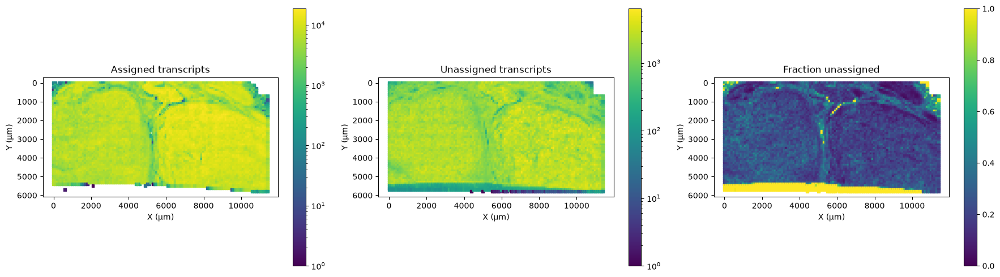

In [29]:
##Visualize spatial assignment QC

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

x = spatial_qc["x_bin"] * bin_size
y = spatial_qc["y_bin"] * bin_size

metrics = [
    ("assigned", "Assigned transcripts"),
    ("unassigned", "Unassigned transcripts"),
    ("fraction_unassigned", "Fraction unassigned")
]

for ax, (metric, title) in zip(axes, metrics):

    values = spatial_qc[metric].to_numpy()

    if metric == "fraction_unassigned":
        vmax = 1
        norm = None
    else:
        vmax = None
        norm = LogNorm(vmin=1, vmax=max(2, values.max()))

    sc_plot = ax.scatter(
        x,
        y,
        c=values,
        s=12,
        marker="s",
        cmap="viridis",
        norm=norm,
        vmin=0 if norm is None else None,
        vmax=vmax,
        rasterized=True
    )

    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("X (µm)")
    ax.set_ylabel("Y (µm)")

    plt.colorbar(sc_plot, ax=ax)

plt.tight_layout()
plt.show()

# Quantify regions with high unassigned transcript fractions

count    6612.000000
mean        0.268034
std         0.180572
min         0.016191
50%         0.228062
90%         0.386679
95%         0.594914
99%         1.000000
max         1.000000
Name: fraction_unassigned, dtype: float64


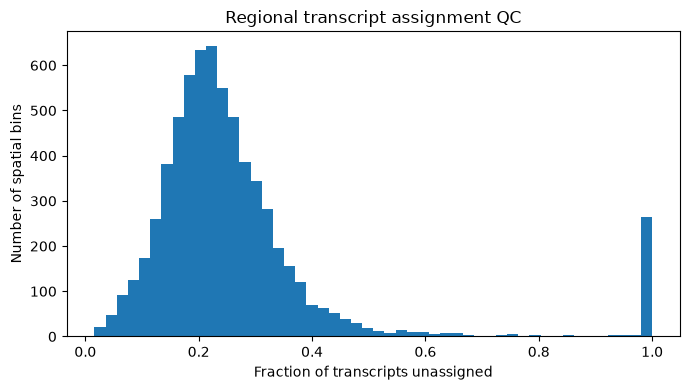

In [30]:
# Restrict to bins with adequate transcript coverage
well_covered = spatial_qc[
    spatial_qc["total"] >= 100
].copy()

print(
    well_covered["fraction_unassigned"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

plt.figure(figsize=(7, 4))

plt.hist(
    well_covered["fraction_unassigned"],
    bins=50
)

plt.xlabel("Fraction of transcripts unassigned")
plt.ylabel("Number of spatial bins")
plt.title("Regional transcript assignment QC")

plt.tight_layout()
plt.show()

## The ~300 bins with 100% unassigned transcripts are regions with no cells.

# How many of the bins with unassigned transcripts correlate with empty (no cell) regions?

In [31]:
# Assign each cell centroid to a spatial bin
cell_x_bin = np.floor(
    adata.obsm["spatial"][:, 0] / bin_size
).astype(int)

cell_y_bin = np.floor(
    adata.obsm["spatial"][:, 1] / bin_size
).astype(int)

cell_bins = pd.DataFrame({
    "x_bin": cell_x_bin,
    "y_bin": cell_y_bin
})

# Count cells per bin
cell_counts = (
    cell_bins.groupby(["x_bin", "y_bin"])
    .size()
    .rename("n_cells")
    .reset_index()
)

# Add cell counts to transcript QC
spatial_qc = spatial_qc.drop(
    columns=["n_cells"], errors="ignore"
).merge(
    cell_counts,
    on=["x_bin", "y_bin"],
    how="left"
)

spatial_qc["n_cells"] = (
    spatial_qc["n_cells"].fillna(0).astype(int)
)

# Compare assignment in bins with and without cells
for label, mask in [
    ("Bins with cells", spatial_qc["n_cells"] > 0),
    ("Bins without cells", spatial_qc["n_cells"] == 0)
]:
    subset = spatial_qc.loc[mask]

    print(f"\n{label}: {len(subset):,} bins")

    if subset["total"].sum() > 0:
        print(
            "Transcript-weighted unassigned fraction:",
            f"{subset['unassigned'].sum() / subset['total'].sum():.2%}"
        )


Bins with cells: 6,340 bins
Transcript-weighted unassigned fraction: 21.45%

Bins without cells: 348 bins
Transcript-weighted unassigned fraction: 99.19%


# Segmentation QC

In [32]:

import seaborn as sns

# Calculate nucleus-to-cell area ratio
adata.obs["nucleus_cell_ratio"] = (
    adata.obs["nucleus_area"] /
    adata.obs["cell_area"].replace(0, np.nan)
)

# Summarize segmentation metrics
metrics = [
    "cell_area",
    "nucleus_area",
    "nucleus_cell_ratio",
    "nucleus_count"
]

print(
    adata.obs[metrics].describe(
        percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
    )
)

# Number of nuclei per cell
print("\nNucleus counts:")
print(adata.obs["nucleus_count"].value_counts().sort_index())

           cell_area   nucleus_area  nucleus_cell_ratio  nucleus_count
count  465534.000000  459288.000000       459288.000000  465534.000000
mean       80.405576      34.417794            0.474618       1.012231
std        78.048052      30.845600            0.174072       0.206349
min         1.445000       0.903125            0.008126       0.000000
1%         10.792344       4.922031            0.085950       0.000000
5%         19.462344       7.179844            0.168856       1.000000
50%        57.348440      27.951720            0.491209       1.000000
95%       224.291102      86.383909            0.729361       1.000000
99%       419.667301     172.903288            0.837281       2.000000
max      1502.167867     829.565499            1.000000       9.000000

Nucleus counts:
nucleus_count
0      6246
1    448086
2     10536
3       615
4        41
5         6
7         2
8         1
9         1
Name: count, dtype: int64


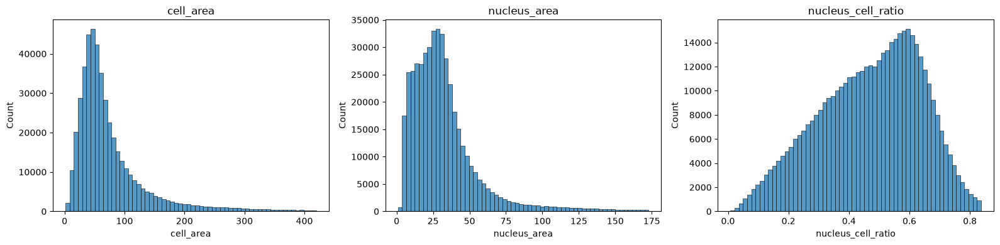

In [33]:
#Visualize the distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = [
    "cell_area",
    "nucleus_area",
    "nucleus_cell_ratio"
]

for ax, metric in zip(axes, metrics):

    values = adata.obs[metric].dropna()

    upper = values.quantile(0.99)

    sns.histplot(
        values[values <= upper],
        bins=60,
        ax=ax
    )

    ax.set_title(metric)
    ax.set_xlabel(metric)

plt.tight_layout()
plt.show()

# Investigate cells with multiple nuclei

In [34]:
# Distribution of nuclei per cell
nucleus_summary = (
    adata.obs["nucleus_count"]
    .value_counts()
    .sort_index()
)

print(nucleus_summary)

print(
    "Percentage of cells with multiple nuclei:",
    f"{(adata.obs['nucleus_count'] > 1).mean():.2%}"
)

nucleus_count
0      6246
1    448086
2     10536
3       615
4        41
5         6
7         2
8         1
9         1
Name: count, dtype: int64
Percentage of cells with multiple nuclei: 2.41%


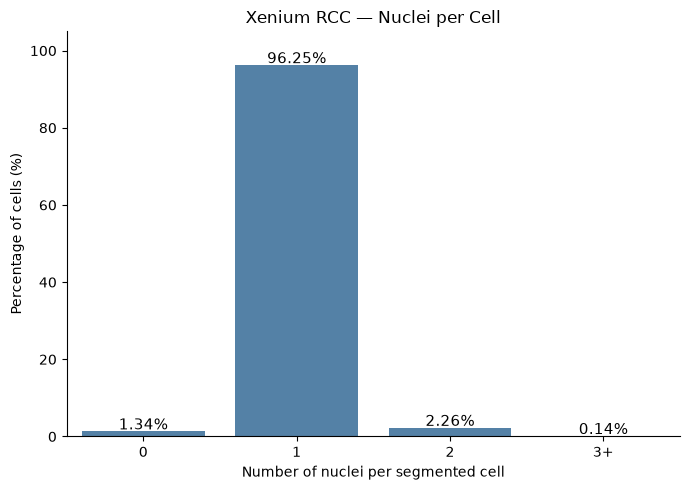

In [35]:
#Bar plot of multi-nucleted cells

# Group nuclei counts
nuclei = adata.obs["nucleus_count"]

categories = pd.Series(
    ["0" if n == 0 else "1" if n == 1 else "2" if n == 2 else "3+"
     for n in nuclei],
    index=adata.obs_names
)

# Calculate percentages
percentages = (
    categories.value_counts(normalize=True)
    .reindex(["0", "1", "2", "3+"])
    .fillna(0) * 100
)

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    x=percentages.index,
    y=percentages.values,
    color="steelblue",
    ax=ax
)

for i, value in enumerate(percentages.values):
    ax.text(
        i, value + 0.5,
        f"{value:.2f}%",
        ha="center",
        fontsize=11
    )

ax.set_xlabel("Number of nuclei per segmented cell")
ax.set_ylabel("Percentage of cells (%)")
ax.set_title("Xenium RCC — Nuclei per Cell")
ax.set_ylim(0, 105)

sns.despine()
plt.tight_layout()
plt.show()

## Compare segmentation metrics with RNA counts

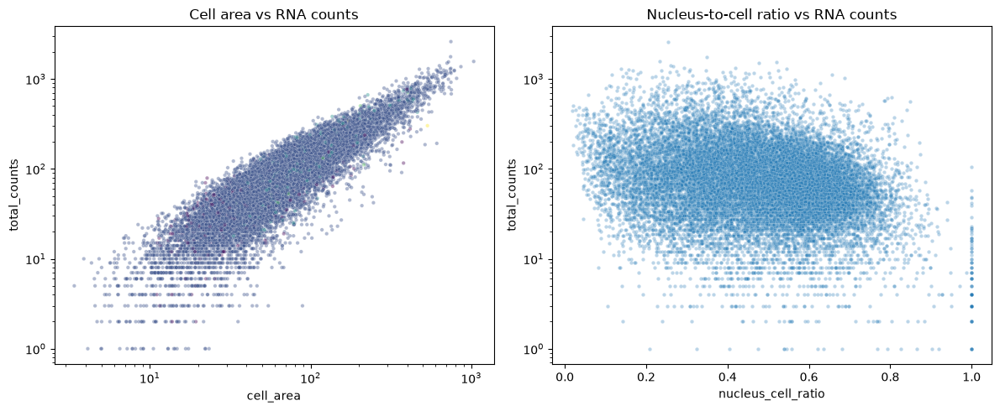

In [36]:
##Compare segmentation metrics with RNA counts

sample = adata.obs.sample(
    n=20000,
    random_state=42
).copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=sample,
    x="cell_area",
    y="total_counts",
    hue="nucleus_count",
    palette="viridis",
    alpha=0.4,
    s=10,
    legend=False,
    ax=axes[0]
)

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Cell area vs RNA counts")

sns.scatterplot(
    data=sample,
    x="nucleus_cell_ratio",
    y="total_counts",
    alpha=0.3,
    s=10,
    ax=axes[1]
)

axes[1].set_yscale("log")
axes[1].set_title("Nucleus-to-cell ratio vs RNA counts")

plt.tight_layout()
plt.show()

In [37]:
##examine cells with ratio of 1


mask = np.isclose(
    adata.obs["nucleus_cell_ratio"].to_numpy(),
    1.0,
    atol=1e-6
)

print(f"Cells with ratio = 1: {mask.sum():,}")
print(f"Percentage of cells: {mask.mean():.2%}")

columns = [
    "cell_area",
    "nucleus_area",
    "nucleus_count",
    "total_counts",
    "n_genes_by_counts",
    "segmentation_method"
]

print(adata.obs.loc[mask, columns].head(10))

print("\nSegmentation methods:")
print(adata.obs.loc[mask, "segmentation_method"].value_counts())

print("\nNucleus counts:")
print(adata.obs.loc[mask, "nucleus_count"].value_counts())

Cells with ratio = 1: 1,820
Percentage of cells: 0.39%
            cell_area  nucleus_area  nucleus_count  total_counts  \
cgpehlok-1  15.759532     15.759532              1          18.0   
jgoidlpk-1  10.340782     10.340782              1           9.0   
leehnlaj-1  11.785782     11.785782              1           3.0   
nmphfiah-1   4.876875      4.876875              1           0.0   
npcdklbk-1   4.470469      4.470469              1           0.0   
oajcgchf-1   5.102656      5.102656              1           0.0   
obkadodg-1   7.586250      7.586250              1           5.0   
obknpddo-1   7.947500      7.947500              1           9.0   
obnnmcno-1  15.488594     15.488594              1          11.0   
ocmjckln-1   2.844844      2.844844              1           2.0   

            n_genes_by_counts  \
cgpehlok-1                 12   
jgoidlpk-1                  7   
leehnlaj-1                  3   
nmphfiah-1                  0   
npcdklbk-1                  0  

In [38]:
# Compare nucleus-only cells with all other cells
adata.obs["nucleus_only_flag"] = np.isclose(
    adata.obs["nucleus_cell_ratio"],
    1.0,
    atol=1e-6
)

summary = (
    adata.obs.groupby("nucleus_only_flag")[
        ["cell_area", "total_counts", "n_genes_by_counts"]
    ]
    .agg(["median", "mean"])
)

print(summary)

# Percentage with zero RNA counts
print("\nPercentage with zero transcripts:")

print(
    adata.obs.groupby("nucleus_only_flag")["total_counts"]
    .apply(lambda x: (x == 0).mean() * 100)
)

                   cell_area            total_counts              \
                      median       mean       median        mean   
nucleus_only_flag                                                  
False              57.483908  80.660439         70.0  106.464226   
True               11.063282  15.469738          7.0   13.182418   

                  n_genes_by_counts             
                             median       mean  
nucleus_only_flag                               
False                          32.0  35.493149  
True                            5.0   8.260989  

Percentage with zero transcripts:
nucleus_only_flag
False    0.041836
True     6.153846
Name: total_counts, dtype: float64


## Cells with nucleus-cell ratio of 1 had poor segmentation

# Calculate Transcript density

In [40]:
# Assign each cell centroid to a spatial bin
cell_x_bin = np.floor(
    adata.obsm["spatial"][:, 0] / bin_size
).astype(int)

cell_y_bin = np.floor(
    adata.obsm["spatial"][:, 1] / bin_size
).astype(int)

cell_bins = pd.DataFrame({
    "x_bin": cell_x_bin,
    "y_bin": cell_y_bin
})

# Count cells per bin
cell_counts = (
    cell_bins.groupby(["x_bin", "y_bin"])
    .size()
    .rename("n_cells")
    .reset_index()
)

# Add cell counts to transcript QC
spatial_qc = spatial_qc.drop(
    columns=["n_cells"], errors="ignore"
).merge(
    cell_counts,
    on=["x_bin", "y_bin"],
    how="left"
)

spatial_qc["n_cells"] = (
    spatial_qc["n_cells"].fillna(0).astype(int)
)

# Compare assignment in bins with and without cells
for label, mask in [
    ("Bins with cells", spatial_qc["n_cells"] > 0),
    ("Bins without cells", spatial_qc["n_cells"] == 0)
]:
    subset = spatial_qc.loc[mask]

    print(f"\n{label}: {len(subset):,} bins")

    if subset["total"].sum() > 0:
        print(
            "Transcript-weighted unassigned fraction:",
            f"{subset['unassigned'].sum() / subset['total'].sum():.2%}"
        )


Bins with cells: 6,340 bins
Transcript-weighted unassigned fraction: 21.45%

Bins without cells: 348 bins
Transcript-weighted unassigned fraction: 99.19%


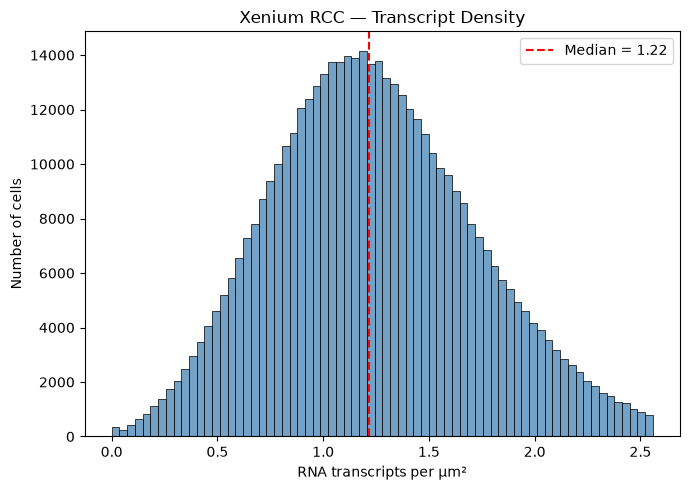

In [41]:

##Visualize the distribution
values = adata.obs["transcript_density"].replace(
    [np.inf, -np.inf], np.nan
).dropna()

upper = values.quantile(0.99)

fig, ax = plt.subplots(figsize=(7, 5))

sns.histplot(
    values[values <= upper],
    bins=70,
    color="steelblue",
    ax=ax
)

ax.axvline(
    values.median(),
    color="red",
    linestyle="--",
    label=f"Median = {values.median():.2f}"
)

ax.set_xlabel("RNA transcripts per µm²")
ax.set_ylabel("Number of cells")
ax.set_title("Xenium RCC — Transcript Density")
ax.legend()

plt.tight_layout()
plt.show()

                      count      mean       std  min       25%       50%  \
nucleus_only_flag                                                          
False              463714.0  1.255079  0.499841  0.0  0.902663  1.217947   
True                 1820.0  0.763174  0.548028  0.0  0.328891  0.664835   

                        75%       max  
nucleus_only_flag                      
False              1.569734  4.429066  
True               1.117041  2.850389  


/tmp/ipykernel_2247795/66853606.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Other cells", "Nucleus-only cells"])


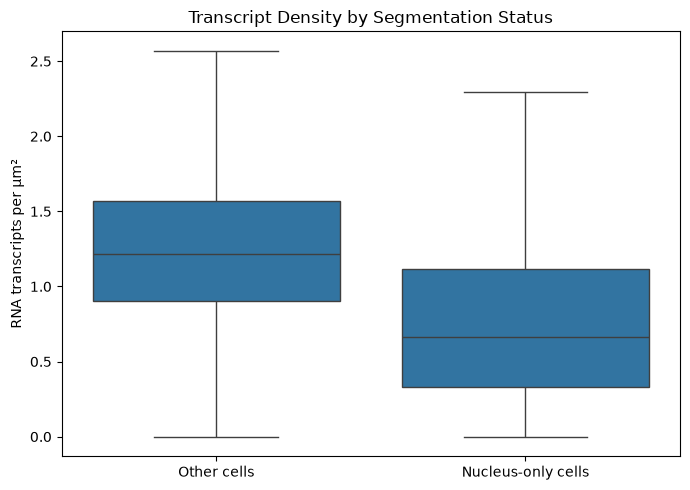

In [42]:
# Compare density distributions
print(
    adata.obs.groupby("nucleus_only_flag")[
        "transcript_density"
    ].describe()
)

fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=adata.obs,
    x="nucleus_only_flag",
    y="transcript_density",
    showfliers=False,
    ax=ax
)

ax.set_xticklabels(["Other cells", "Nucleus-only cells"])
ax.set_xlabel("")
ax.set_ylabel("RNA transcripts per µm²")
ax.set_title("Transcript Density by Segmentation Status")

plt.tight_layout()
plt.show()

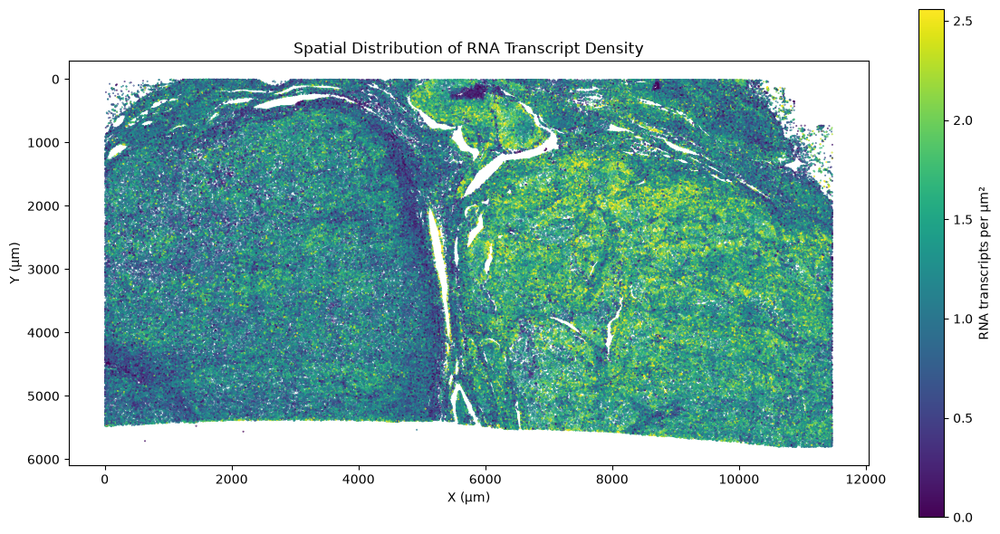

In [43]:
xy = adata.obsm["spatial"]

density = adata.obs["transcript_density"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 6))

sc = ax.scatter(
    xy[:, 0],
    xy[:, 1],
    c=density,
    s=0.15,
    cmap="viridis",
    vmin=0,
    vmax=np.nanpercentile(density, 99),
    rasterized=True
)

ax.invert_yaxis()
ax.set_aspect("equal")

ax.set_xlabel("X (µm)")
ax.set_ylabel("Y (µm)")
ax.set_title("Spatial Distribution of RNA Transcript Density")

plt.colorbar(
    sc,
    ax=ax,
    label="RNA transcripts per µm²"
)

plt.tight_layout()
plt.show()

# Quantifying spatial transcript differences

In [44]:
# Approximate division based on the visible tissue structure
x = adata.obsm["spatial"][:, 0]

adata.obs["tissue_region"] = np.where(
    x < 6000,
    "Left",
    "Right"
)

summary = (
    adata.obs.groupby("tissue_region")[
        ["total_counts", "cell_area", "transcript_density"]
    ]
    .median()
)

print(summary)

               total_counts  cell_area  transcript_density
tissue_region                                             
Left                   62.0  56.580783            1.075886
Right                  79.0  58.116096            1.366179


## Slightly higher transcript density on the right side of the tissue

# Fidelity analysis

In [45]:
# Extract gene panel
import json

with open(path+"/gene_panel.json") as f:
    panel = json.load(f)

print(panel.keys())

dict_keys(['metadata', 'payload'])


In [46]:
print(type(panel["payload"]))

if isinstance(panel["payload"], dict):
    print(panel["payload"].keys())
elif isinstance(panel["payload"], list):
    print(panel["payload"][:2])

<class 'dict'>
dict_keys(['chemistry', 'customer', 'designer', 'panel', 'spec_version', 'targets'])


In [47]:
##Inspect targets and extract targets
targets = panel["payload"]["targets"]

print("Type:", type(targets))
print("Number of targets:", len(targets))

if isinstance(targets, list):
    print("First target:", targets[0])
elif isinstance(targets, dict):
    print("First target keys:", list(targets.keys())[:5])
    first_target = next(iter(targets.values()))
    print("First target value:", first_target)



gene_panel = pd.DataFrame([
    {
        "gene_symbol": target["type"]["data"]["name"],
        "ensembl_id": target["type"]["data"]["id"],
        "gene_coverage": target.get("info", {}).get("gene_coverage"),
        "source_category": target.get("source", {}).get("category")
    }
    for target in targets
    if target.get("type", {}).get("descriptor") == "gene"
])

print("Number of gene targets:", len(gene_panel))
print(gene_panel.head(10))

Type: <class 'list'>
Number of targets: 465
First target: {'codewords': [419], 'info': {'gene_coverage': 8}, 'source': {'category': 'current', 'identity': {'design_id': 'N/A', 'name': 'Human Multi-Tissue and Cancer Panel + Custom Addon', 'version': '1.0.0'}}, 'type': {'data': {'id': 'ENSG00000107796', 'name': 'ACTA2'}, 'descriptor': 'gene'}}
Number of gene targets: 430
  gene_symbol         ensembl_id  gene_coverage source_category
0       ACTA2    ENSG00000107796              8         current
1      ATP1A1    ENSG00000163399              8         current
2        BCL2    ENSG00000171791              8         current
3       CD163    ENSG00000177575              8         current
4       CD274    ENSG00000120217              8         current
5        CD3D    ENSG00000167286              4         current
6        CD3E    ENSG00000198851              8         current
7        CD3G    ENSG00000160654              7         current
8         CD4    ENSG00000010610              8     

In [48]:
##Compare panel against expressed genes
panel_genes = set(gene_panel["gene_symbol"])
adata_genes = set(adata.var_names)

print("Genes in panel:", len(panel_genes))
print("Genes in AnnData:", len(adata_genes))

print("Shared genes:", len(panel_genes & adata_genes))

print("\nPanel genes missing from AnnData:")
print(sorted(panel_genes - adata_genes))

print("\nAnnData genes absent from panel:")
print(sorted(adata_genes - panel_genes))

Genes in panel: 405
Genes in AnnData: 405
Shared genes: 405

Panel genes missing from AnnData:
[]

AnnData genes absent from panel:
[]


In [49]:
# Display all genes in the actual Xenium RNA panel
all_genes = sorted(gene_panel["gene_symbol"].unique())

print(f"Total genes: {len(all_genes)}")
print(", ".join(all_genes))

Total genes: 405
ABCC11, ACE2, ACKR1, ACTA2, ACTG2, ADAM28, ADAMTS1, ADGRE1, ADGRL4, ADH1C, ADH4, ADIPOQ, AGER, AGR3, AHSP, AIF1, ALAS2, ALDH1A3, AMY2A, ANGPT2, ANPEP, APCDD1, APOA5, APOBEC3A, APOLD1, AQP2, AQP3, AQP8, AQP9, AR, ARFGEF3, ASCL1, ASCL3, ASPN, ATP1A1, BAMBI, BANK1, BASP1, BBOX1, BCL2, BCL2L11, BMX, BTNL9, C15orf48, C1orf162, C1orf194, C20orf85, C5orf46, C6orf118, C7, CA4, CAPN8, CAV1, CAVIN1, CAVIN2, CCDC39, CCDC78, CCL19, CCL27, CCL5, CCNB2, CCR2, CCR7, CD14, CD163, CD19, CD1A, CD1C, CD1E, CD2, CD247, CD27, CD274, CD28, CD300E, CD34, CD3D, CD3E, CD3G, CD4, CD45RA, CD45RO, CD5L, CD68, CD69, CD70, CD79A, CD83, CD86, CD8A, CD93, CDH1, CDH16, CDH2, CDK1, CENPF, CFAP53, CFB, CFHR1, CFHR3, CFTR, CHGA, CLCA1, CLCA2, CLEC10A, CLEC14A, CLEC4E, CLECL1, CLIC6, CNN1, COCH, COL17A1, COL5A2, CPA3, CRHBP, CRISPLD2, CSF2RA, CSF3, CTLA4, CTNNB1, CTSG, CTSK, CXCL10, CXCL2, CXCL6, CXCL9, CXCR4, CYP1A1, CYP2A7, CYP2B6, CYP2F1, CYP3A4, CYP4B1, CYTIP, DERL3, DES, DIRAS3, DMBT1, DNAAF1, DNASE1

In [50]:


# ============================================================
# 1. Define cell-type markers
#    Simplified immune hierarchy + nonimmune populations
# ============================================================

marker_dict = {

    # ------------------------
    # LYMPHOID
    # ------------------------
    "T cells": [
        "CD3D", "CD3E", "CD3G"
    ],

    "B cells": [
        "MS4A1", "CD79A"
    ],

    "NK cells": [
        "KLRD1", "GNLY", "PRF1", "NKG7"
    ],

    # ------------------------
    # MYELOID
    # ------------------------
    "Macrophages / monocytes": [
        "CD68", "CD163"
    ],

    "Dendritic cells": [
        "FCER1A", "CD1C", "LAMP3"
    ],

    "Neutrophils": [
        "FCGR3B"
    ],

    # ------------------------
    # EPITHELIAL / RENAL
    # ------------------------
    "Epithelial / RCC candidates": [
        "KRT8", "KRT18", "EPCAM", "CDH1", "VIM"
    ],

    "Renal tubular subtypes": [
        "UMOD", "AQP2"
    ],

    # ------------------------
    # STROMAL
    # ------------------------
    "Fibroblast / stromal": [
        "PDGFRA", "PDGFRB", "THY1", "ACTA2"
    ],

    "Pericytes / smooth muscle": [
        "MYH11", "CNN1"
    ],

    # ------------------------
    # VASCULAR
    # ------------------------
    "Endothelial cells": [
        "PECAM1", "VWF"
    ]
}

# ============================================================
# 2. Use raw RNA counts
# ============================================================

X = (
    adata.layers["counts"]
    if "counts" in adata.layers
    else adata.X
)

gene_to_idx = {
    gene: i for i, gene in enumerate(adata.var_names)
}

results = []

# ============================================================
# 3. Calculate marker expression statistics
# ============================================================

for cell_type, genes in marker_dict.items():

    for gene in genes:

        if gene not in gene_to_idx:
            print(f"Skipping {gene}: not in Xenium panel")
            continue

        idx = gene_to_idx[gene]
        x = X[:, idx]

        counts = (
            x.toarray().ravel()
            if sparse.issparse(x)
            else np.asarray(x).ravel()
        )

        positive = counts > 0

        results.append({
            "cell_type": cell_type,
            "gene": gene,
            "pct_positive": 100 * positive.mean(),
            "mean_counts": counts.mean(),
            "mean_counts_positive": (
                counts[positive].mean()
                if positive.any() else 0
            ),
            "max_counts": counts.max()
        })

# ============================================================
# 4. Rank markers within each population
# ============================================================

marker_stats = pd.DataFrame(results)

marker_stats = marker_stats.sort_values(
    ["cell_type", "pct_positive", "mean_counts_positive"],
    ascending=[True, False, False]
).reset_index(drop=True)

marker_stats["rank"] = (
    marker_stats.groupby("cell_type").cumcount() + 1
)

print("\nALL MARKER RANKINGS\n")
print(marker_stats.to_string(index=False))

# ============================================================
# 5. Extract top 3 markers per population
# ============================================================

top_markers = (
    marker_stats
    .groupby("cell_type", group_keys=False)
    .head(3)
    .reset_index(drop=True)
)

print("\nTOP 3 MARKERS PER POPULATION\n")
print(top_markers.to_string(index=False))

# ============================================================
# 6. Save results
# ============================================================

output_dir = Path(
    "/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/Xenium_test"
)

marker_stats.to_csv(
    output_dir / "Xenium_simplified_celltype_marker_rankings.csv",
    index=False
)

top_markers.to_csv(
    output_dir / "Xenium_simplified_top3_markers.csv",
    index=False
)

print("\nSaved rankings successfully.")



ALL MARKER RANKINGS

                  cell_type   gene  pct_positive  mean_counts  mean_counts_positive  max_counts  rank
                    B cells  MS4A1      9.762767     0.434791              4.453563        86.0     1
                    B cells  CD79A      8.459318     0.172503              2.039207        29.0     2
            Dendritic cells  LAMP3      3.848054     0.054933              1.427543        25.0     1
            Dendritic cells   CD1C      2.257408     0.031184              1.381387        19.0     2
            Dendritic cells FCER1A      0.797364     0.009823              1.231950         7.0     3
          Endothelial cells PECAM1     44.073043     1.406774              3.191914        56.0     1
          Endothelial cells    VWF     13.819184     0.408282              2.954456        46.0     2
Epithelial / RCC candidates    VIM     94.265940    20.747875             22.009937       752.0     1
Epithelial / RCC candidates  KRT18     30.357611     0.94720

# Evaluate Marker Co-expression

In [51]:

# Expected coexpression pairs
marker_pairs = {
    "T cells": ("CD3E", "CD3D"),
    "B cells": ("MS4A1", "CD79A"),
    "NK cells": ("KLRD1", "GNLY"),
    "Macrophages / monocytes": ("CD68", "CD163"),
    "Dendritic cells": ("CD1C", "FCER1A"),
    "Endothelial cells": ("PECAM1", "VWF"),
    "Epithelial cells": ("KRT8", "KRT18"),
    "Fibroblast / stromal": ("PDGFRA", "THY1"),
    "Smooth muscle": ("MYH11", "CNN1")
}

X = adata.layers["counts"] if "counts" in adata.layers else adata.X

results = []

for cell_type, (g1, g2) in marker_pairs.items():

    if g1 not in adata.var_names or g2 not in adata.var_names:
        continue

    idx = [adata.var_names.get_loc(g) for g in (g1, g2)]
    sub = X[:, idx]

    if sparse.issparse(sub):
        sub = sub.toarray()
    else:
        sub = np.asarray(sub)

    p1 = sub[:, 0] > 0
    p2 = sub[:, 1] > 0

    both = p1 & p2
    either = p1 | p2

    observed = both.mean()
    expected = p1.mean() * p2.mean()

    results.append({
        "cell_type": cell_type,
        "marker_1": g1,
        "marker_2": g2,
        "both_positive_pct": 100 * observed,
        "either_positive_pct": 100 * either.mean(),
        "jaccard_overlap": (
            both.sum() / either.sum()
            if either.sum() else np.nan
        ),
        "observed_expected_ratio": (
            observed / expected
            if expected > 0 else np.nan
        )
    })

coexpression_df = pd.DataFrame(results)

print(
    coexpression_df.sort_values(
        "observed_expected_ratio",
        ascending=False
    ).to_string(index=False)
)


              cell_type marker_1 marker_2  both_positive_pct  either_positive_pct  jaccard_overlap  observed_expected_ratio
          Smooth muscle    MYH11     CNN1           0.853429             6.321558         0.135003                 6.842560
               NK cells    KLRD1     GNLY           0.453028             5.139474         0.088147                 5.810944
                B cells    MS4A1    CD79A           4.222463            13.999622         0.301613                 5.112785
        Dendritic cells     CD1C   FCER1A           0.057353             2.997418         0.019134                 3.186349
                T cells     CD3E     CD3D           9.086769            35.072626         0.259084                 2.082972
       Epithelial cells     KRT8    KRT18          16.570863            43.777683         0.378523                 1.820068
   Fibroblast / stromal   PDGFRA     THY1           2.346767            24.899363         0.094250                 1.788424
      En

In [52]:
# Check how many cells we have 
print(f"Total number of cells: {adata.n_obs:,}")

Total number of cells: 465,534


In [55]:
import scanpy as sc


# Use ALL cells instead of randomly selecting 50,000
adata_clust = adata.copy()

# Start from original RNA counts
if "counts" in adata_clust.layers:
    adata_clust.X = adata_clust.layers["counts"].copy()

print("Cells before filtering:", adata_clust.n_obs)

# Filter low-quality cells
sc.pp.filter_cells(
    adata_clust,
    min_genes=5
)

print("Cells after filtering:", adata_clust.n_obs)

# Normalize and log transform
sc.pp.normalize_total(
    adata_clust,
    target_sum=1e4
)

sc.pp.log1p(adata_clust)

# PCA
sc.pp.pca(
    adata_clust,
    n_comps=30,
    svd_solver="arpack"
)

# Nearest neighbors
sc.pp.neighbors(
    adata_clust,
    n_neighbors=15,
    n_pcs=30
)

# Leiden clustering
sc.tl.leiden(
    adata_clust,
    resolution=0.5,
    key_added="leiden",
    flavor="igraph",
    n_iterations=2,
    directed=False
)

print("\nCluster sizes:")
print(
    adata_clust.obs["leiden"]
    .value_counts()
    .sort_index()
)

Cells before filtering: 465534
Cells after filtering: 459859

Cluster sizes:
leiden
0     45058
1     65311
2     27869
3     64414
4      2796
5    101567
6     23306
7     97473
8     13802
9     18263
Name: count, dtype: int64


In [56]:
adata_clust.write_h5ad(
    "/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/Xenium_test/Xenium_full_RNA_leiden_clusters.h5ad"
)

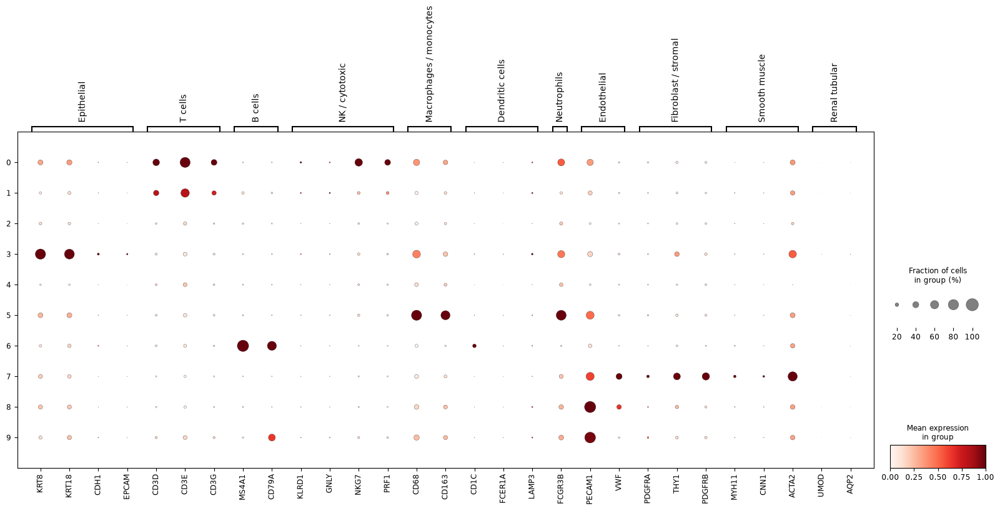

In [58]:


markers = {
    "Epithelial": ["KRT8", "KRT18", "CDH1", "EPCAM"],
    "T cells": ["CD3D", "CD3E", "CD3G"],
    "B cells": ["MS4A1", "CD79A"],
    "NK / cytotoxic": ["KLRD1", "GNLY", "NKG7", "PRF1"],
    "Macrophages / monocytes": ["CD68", "CD163"],
    "Dendritic cells": ["CD1C", "FCER1A", "LAMP3"],
    "Neutrophils": ["FCGR3B"],
    "Endothelial": ["PECAM1", "VWF"],
    "Fibroblast / stromal": ["PDGFRA", "THY1", "PDGFRB"],
    "Smooth muscle": ["MYH11", "CNN1", "ACTA2"],
    "Renal tubular": ["UMOD", "AQP2"]
}

# Keep only genes represented in the Xenium panel
markers = {
    group: [g for g in genes if g in adata_clust.var_names]
    for group, genes in markers.items()
}

sc.pl.dotplot(
    adata_clust,
    var_names=markers,
    groupby="leiden",
    standard_scale="var",
    figsize=(20, 7),
    show=True
)

In [60]:
sc.tl.rank_genes_groups(
    adata_clust,
    groupby="leiden",
    method="wilcoxon",
    use_raw=False
)

cluster_markers = sc.get.rank_genes_groups_df(
    adata_clust,
    group=None
)

# Top 10 genes for each cluster
top_markers = (
    cluster_markers
    .sort_values(
        ["group", "scores"],
        ascending=[True, False]
    )
    .groupby("group")
    .head(10)
)

display(
    top_markers[
        ["group", "names", "logfoldchanges", "pvals_adj"]
    ]
)

,group,names,logfoldchanges,pvals_adj
0,0,CD8A,6.343137,0.0
1,0,CCL5,5.612672,0.0
2,0,CD3E,4.956091,0.0
3,0,CD2,4.937177,0.0
4,0,GZMK,4.835938,0.0
...,...,...,...,...
3650,9,PECAM1,4.320405,0.0
3651,9,FKBP11,5.269818,0.0
3652,9,BCL2L11,4.276478,0.0
3653,9,TNFRSF17,6.242440,0.0


In [61]:


path = Path(
    "/mnt/research/HFHMSU-Pancreas/"
    "AlmaP_Project_data/Xenium_test"
)


cluster_markers.to_csv(
     "/mnt/research/HFHMSU-Pancreas/"
    "AlmaP_Project_data/Xenium_test/Xenium_cluster_markers.csv",
    index=False
)

print("Clustering results saved!")

Clustering results saved!


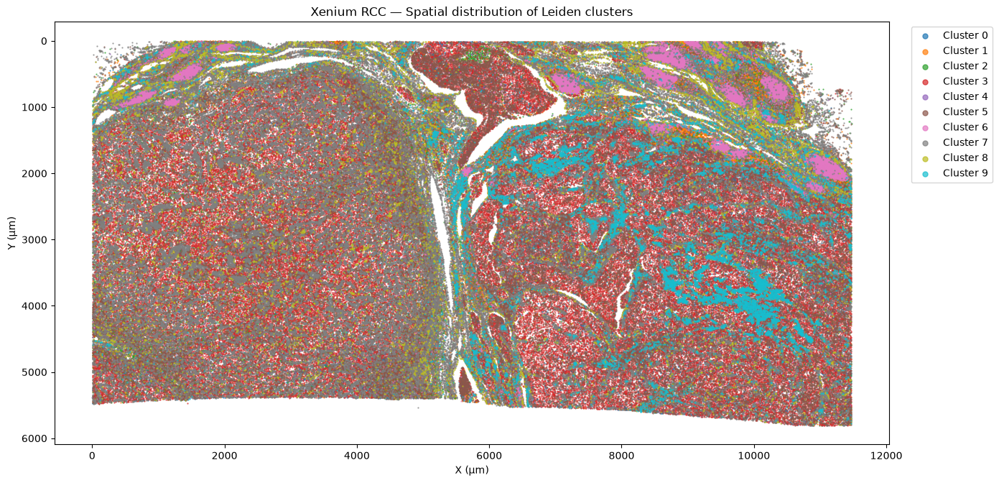

In [62]:


coords = adata_clust.obsm["spatial"]
clusters = adata_clust.obs["leiden"].astype(str)

fig, ax = plt.subplots(figsize=(14, 12))

cluster_ids = sorted(clusters.unique(), key=int)
colors = plt.get_cmap("tab10")

for i, cluster in enumerate(cluster_ids):
    mask = (clusters == cluster).to_numpy()

    ax.scatter(
        coords[mask, 0],
        coords[mask, 1],
        s=0.4,
        color=colors(i),
        label=f"Cluster {cluster}",
        alpha=0.7,
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_xlabel("X (µm)")
ax.set_ylabel("Y (µm)")
ax.set_title("Xenium RCC — Spatial distribution of Leiden clusters")
ax.legend(markerscale=8, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

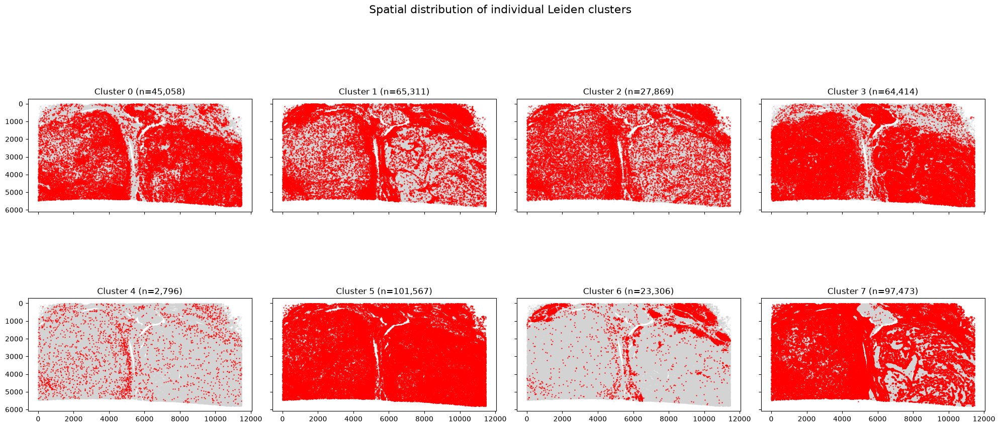

In [63]:
##Plot all 7 clusters separately



coords = adata_clust.obsm["spatial"]
clusters = adata_clust.obs["leiden"].astype(str).to_numpy()

fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharex=True, sharey=True)

for ax, cluster in zip(axes.flat, sorted(np.unique(clusters), key=int)):
    mask = clusters == cluster

    # Background: all sampled cells
    ax.scatter(
        coords[:, 0], coords[:, 1],
        s=0.15, color="lightgray", alpha=0.3,
        rasterized=True
    )

    # Highlight selected cluster
    ax.scatter(
        coords[mask, 0], coords[mask, 1],
        s=0.6, color="red", alpha=0.8,
        rasterized=True
    )

    ax.set_title(f"Cluster {cluster} (n={mask.sum():,})")
    ax.set_aspect("equal")

# Hide unused subplot
for ax in axes.flat[len(np.unique(clusters)):]:
    ax.axis("off")

axes[0, 0].invert_yaxis()

plt.suptitle("Spatial distribution of individual Leiden clusters", fontsize=16)
plt.tight_layout()
plt.show()


# ID cluster biological identities

In [64]:

# Uses the cluster_markers dataframe you already calculated

top5 = (
    cluster_markers
    .sort_values(["group", "scores"], ascending=[True, False])
    .groupby("group")
    .head(5)
    .groupby("group")["names"]
    .apply(lambda x: ", ".join(x))
    .reset_index(name="Top 5 markers")
)

display(top5)


,group,Top 5 markers
0,0,"CD8A, CCL5, CD3E, CD2, GZMK"
1,1,"PTPRC, CD3E, IL7R, TRAC, CXCR4"
2,2,"VIM, CD45RA, CRHBP, LY6D, MYBPC1"
3,3,"VIM, MET, CXCL6, SEMA3C, KRT8"
4,4,"PTEN, VIM, CD45RA, RETN, MYBPC1"
5,5,"HLA-DRA, FCGR3A, HLA-DRB1, MS4A6A, CD68"
6,6,"MS4A1, CXCR4, CD79A, BANK1, IRF8"
7,7,"ACTA2, PDGFRB, THY1, APOLD1, CAVIN1"
8,8,"TFPI, PROX1, PECAM1, MMRN1, LYVE1"
9,9,"MZB1, TENT5C, SLAMF7, SDC1, PRDM1"


# Annotate clusters

In [65]:
celltype_map = {
    "0": "T cells",
    "1": "Macrophages / monocytes",
    "2": "Stromal / fibroblast-like",
    "3": "Epithelial",
    "4": "Endothelial / vascular",
    "5": "B cells",
    "6": "Endothelial / mixed"
}

adata_clust.obs["cell_type"] = (
    adata_clust.obs["leiden"]
    .astype(str)
    .map(celltype_map)
    .astype("category")
)

print(adata_clust.obs["cell_type"].value_counts())

cell_type
B cells                      101567
Macrophages / monocytes       65311
Epithelial                    64414
T cells                       45058
Stromal / fibroblast-like     27869
Endothelial / mixed           23306
Endothelial / vascular         2796
Name: count, dtype: int64


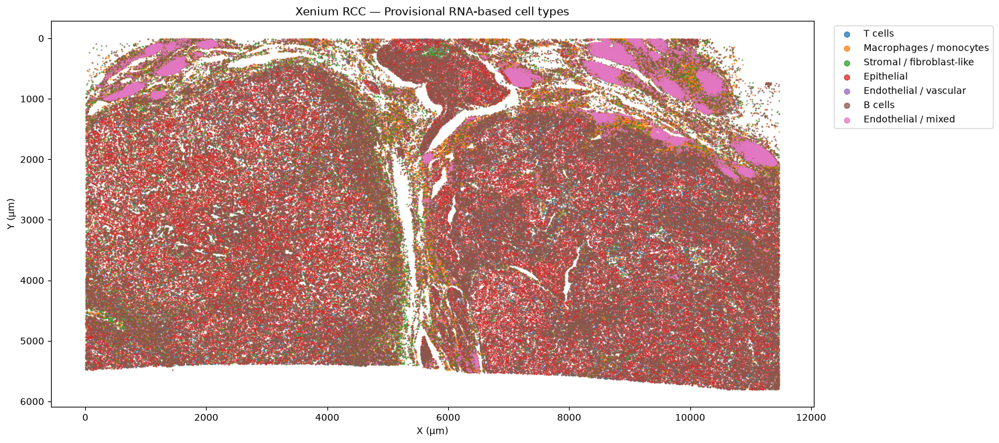

In [81]:
#plot annotated clusters

coords = adata_clust.obsm["spatial"]
labels = (
    adata_clust.obs["cell_type"]
    .astype("object")
    .fillna("Unassigned")
    .astype(str)
    .to_numpy()
)

fig, ax = plt.subplots(figsize=(15, 10))

cell_types = list(celltype_map.values())
colors = plt.get_cmap("tab10")

for i, cell_type in enumerate(cell_types):
    mask = labels == cell_type

    ax.scatter(
        coords[mask, 0],
        coords[mask, 1],
        s=0.5,
        color=colors(i),
        label=cell_type,
        alpha=0.75,
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_xlabel("X (µm)")
ax.set_ylabel("Y (µm)")
ax.set_title("Xenium RCC — Provisional RNA-based cell types")
ax.legend(
    markerscale=8,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## Morphology analysis

In [67]:
import tifffile
#Find morphology images
morph_dir = path / "morphology_focus"

for f in sorted(morph_dir.glob("*.ome.tif")):
    with tifffile.TiffFile(f) as tif:
        series = tif.series[0]
        print(f"{f.name}: shape={series.shape}, axes={series.axes}")

ch0000_dapi.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0001_atp1a1_cd45_e-cadherin.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0002_18s.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0003_alphasma_vimentin.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0004_blue_background.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0005_green_background.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0006_yellow_background.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0007_red_background.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0008_cd4.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0009_cd20.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0010_cd8a.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0011_cd3e.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0012_cd138.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0013_hla-dr.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0014_cd11c.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0015_cd68.ome.tif: shape=(35, 27328, 54002), axes=CYX
ch0016_cd16.ome.tif: shap

In [68]:


#Check morphology file size, shape, and metadata
path = Path("/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/Xenium_test")

for f in sorted(path.rglob("*dapi*.ome.tif")):
    with tifffile.TiffFile(f) as tif:
        print("File:", f.relative_to(path))
        print("Shape:", tif.series[0].shape)
        print("Axes:", tif.series[0].axes)
        print("OME metadata:", (tif.ome_metadata or "")[:1500])

File: morphology_focus/ch0000_dapi.ome.tif
Shape: (35, 27328, 54002)
Axes: CYX
OME metadata: <OME xmlns="http://www.openmicroscopy.org/Schemas/OME/2016-06" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.openmicroscopy.org/Schemas/OME/2016-06 http://www.openmicroscopy.org/Schemas/OME/2016-06/ome.xsd" UUID="urn:uuid:829f05ee-93eb-11f0-b9b0-3cecefaf452c">
  <Plate ID="Plate:0" WellOriginX="0.0" WellOriginXUnit="µm" WellOriginY="0.0" WellOriginYUnit="µm"/>
  <Instrument ID="Instrument:0">
    <Microscope Manufacturer="10x Genomics" Model="Xenium"/>
  </Instrument>
  <Image ID="Image:0">
    <InstrumentRef ID="Instrument:0"/>
    <Pixels ID="Pixels:0" DimensionOrder="XYZCT" Type="uint16" SizeX="54002" SizeY="27328" SizeZ="1" SizeC="35" SizeT="1" PhysicalSizeX="0.2125" PhysicalSizeXUnit="µm" PhysicalSizeY="0.2125" PhysicalSizeYUnit="µm">
      <Channel ID="Channel:0" Name="DAPI" SamplesPerPixel="1">
        <AnnotationRef ID="Annotation:0"/>
      </Chan

In [69]:
import json
#Check pixel size and segmentation metadata

with open(path / "experiment.xenium") as f:
    experiment = json.load(f)

print("Experiment metadata:")
print(json.dumps(experiment, indent=2)[:3000])

dapi = path / "morphology_focus/ch0000_dapi.ome.tif"

with tifffile.TiffFile(dapi) as tif:
    xml = tif.ome_metadata or ""
    print("\nPixel size metadata:")
    import re
    print(re.findall(r'PhysicalSize[XY]="[^"]+"', xml)[:4])
    print("\nImage levels:", len(tif.series[0].levels))

Experiment metadata:
{
  "major_version": 6,
  "minor_version": 0,
  "patch_version": 0,
  "run_name": "Human FFPE Kidney",
  "run_start_time": "2025-05-31T00:05:12Z",
  "region_name": "Human Renal Cell Carcinoma (FFPE)",
  "preservation_method": "FFPE",
  "num_cells": 465534,
  "transcripts_per_cell": 70,
  "transcripts_per_100um": 131.95545437536452,
  "region_area": 66006974.044062495,
  "total_cell_area": 37431529.62779039,
  "thickness_of_high_quality_decoded_transcripts": 4.432465895007049,
  "non_zero_matrix_entries": 16480063,
  "nuclear_transcripts_per_100um": 140.23542022191094,
  "num_transcripts": 76957210,
  "num_transcripts_high_quality": 62948437,
  "fraction_transcripts_assigned": 0.7846572107898406,
  "segmented_cell_stain_frac": 0.9932615018451928,
  "segmented_cell_boundary_frac": 0.3850116210631232,
  "segmented_cell_interior_frac": 0.6082498807820697,
  "segmented_cell_nuc_expansion_frac": 0.006738498154807168,
  "segmented_nucleus_focus_count": 445131,
  "segmente

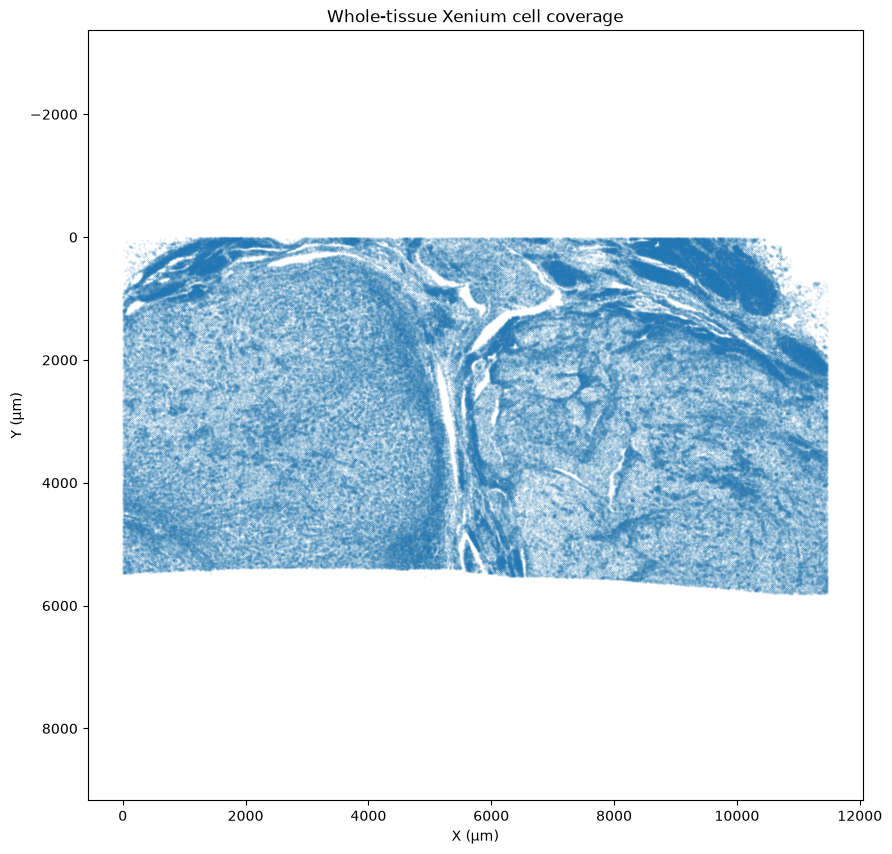

In [70]:
##Visualize morphology images


coords = adata_clust.obsm["spatial"]

plt.figure(figsize=(10, 10))

plt.scatter(
    coords[:, 0],
    coords[:, 1],
    s=0.05,
    alpha=0.3,
    rasterized=True
)

plt.gca().invert_yaxis()
plt.axis("equal")
plt.xlabel("X (µm)")
plt.ylabel("Y (µm)")
plt.title("Whole-tissue Xenium cell coverage")
plt.show()



# Convert spatial coordinates to image pixels
#px0, px1 = int(x0 / pixel_size), int(x1 / pixel_size)
#py0, py1 = int(y0 / pixel_size), int(y1 / pixel_size)

In [72]:

#Load the entire image at full resolution and overlay cells with the DAPI image
dapi_file = path / "morphology_focus/ch0000_dapi.ome.tif"

with tifffile.TiffFile(dapi_file) as tif:
    store = tif.series[0].aszarr()
    try:
        root = zarr.open(store, mode="r")

        # Select the actual image array, not the Zarr group
        if isinstance(root, zarr.Group):
            img = root["0"]
        else:
            img = root

        # DAPI is channel 0
        dapi_full = np.asarray(img[0, :, :])
    finally:
        store.close()

print("DAPI  loaded:", dapi_full.shape)

DAPI  loaded: (27328, 54002)


In [73]:
#verify coordinate alignment
pixel_size = 0.2125  # µm/pixel; verify against image metadata

coords = adata_clust.obsm["spatial"]

x_pixels = coords[:, 0] / pixel_size
y_pixels = coords[:, 1] / pixel_size

# Check and Expand Cluster annotations for morphology overlay

In [85]:
print(adata_clust.obs["cell_type"].isna().sum())
print(adata_clust.obs["cell_type"].value_counts(dropna=False))

129538
cell_type
NaN                          129538
B cells                      101567
Macrophages / monocytes       65311
Epithelial                    64414
T cells                       45058
Stromal / fibroblast-like     27869
Endothelial / mixed           23306
Endothelial / vascular         2796
Name: count, dtype: int64


In [86]:

cluster_annotation = pd.crosstab(
    adata_clust.obs["leiden"].astype(str),
    adata_clust.obs["cell_type"]
        .astype("object")
        .fillna("Unassigned")
        .astype(str)
)

display(cluster_annotation)

cell_type,B cells,Endothelial / mixed,Endothelial / vascular,Epithelial,Macrophages / monocytes,Stromal / fibroblast-like,T cells,Unassigned
leiden,,,,,,,,
0,0,0,0,0,0,0,45058,0
1,0,0,0,0,65311,0,0,0
2,0,0,0,0,0,27869,0,0
3,0,0,0,64414,0,0,0,0
4,0,0,2796,0,0,0,0,0
5,101567,0,0,0,0,0,0,0
6,0,23306,0,0,0,0,0,0
7,0,0,0,0,0,0,0,97473
8,0,0,0,0,0,0,0,13802


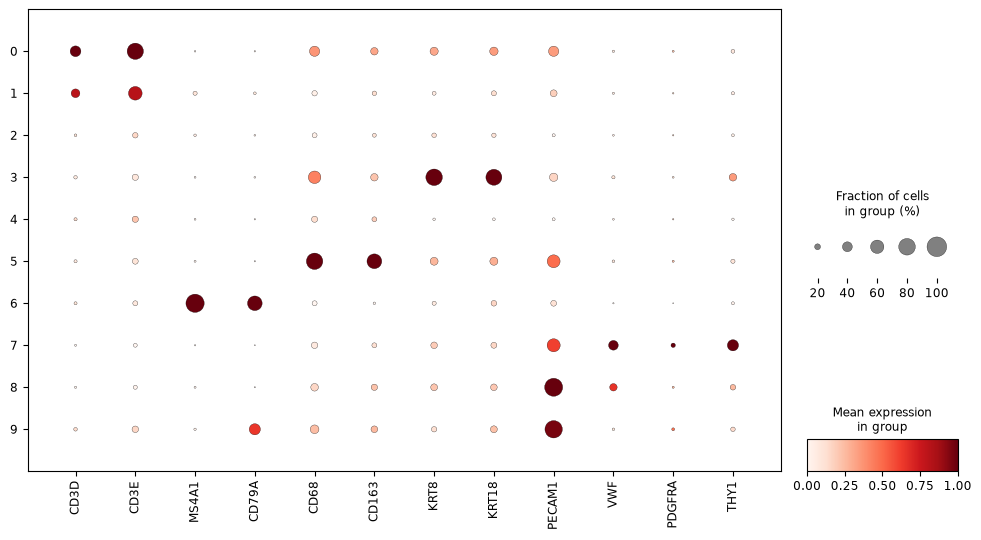

In [87]:
##Compare canonical markers accross leiden clusters


marker_genes = [
    "CD3D", "CD3E",       # T cells
    "MS4A1", "CD79A",     # B cells
    "CD68", "CD163",      # Macrophages
    "KRT8", "KRT18",      # Epithelial
    "PECAM1", "VWF",      # Endothelial
    "PDGFRA", "THY1"      # Stromal
]

# Only use genes present in the Xenium panel
marker_genes = [
    gene for gene in marker_genes
    if gene in adata_clust.var_names
]

sc.pl.dotplot(
    adata_clust,
    var_names=marker_genes,
    groupby="leiden",
    standard_scale="var",
    figsize=(12, 6)
)

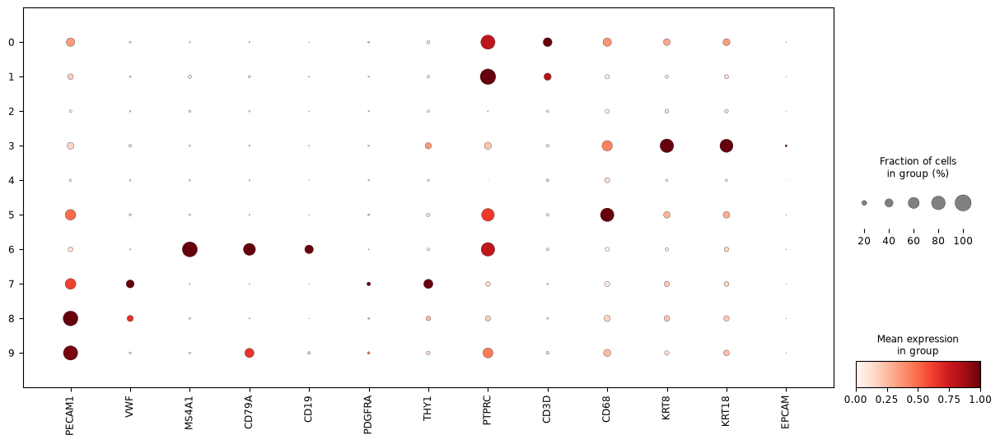

In [88]:
#Explore additional endothelial, stromal, and immune markers to distinguish cluster 6-9
additional_markers = [
    # Endothelial
    "PECAM1", "VWF", "CDH5", "KDR", "EMCN", "ENG",

    # B cells
    "MS4A1", "CD79A", "CD79B", "CD19",

    # Stromal
    "PDGFRA", "COL1A1", "COL1A2", "DCN", "THY1",

    # Immune
    "PTPRC", "CD3D", "CD68",

    # Epithelial
    "KRT8", "KRT18", "EPCAM"
]

additional_markers = [
    gene for gene in additional_markers
    if gene in adata_clust.var_names
]

sc.pl.dotplot(
    adata_clust,
    var_names=additional_markers,
    groupby="leiden",
    standard_scale="var",
    figsize=(15, 6)
)

In [89]:
for cluster in ["6", "7", "8", "9"]:
    print(f"\n=== Leiden cluster {cluster} ===")

    display(
        sc.get.rank_genes_groups_df(
            adata_clust,
            group=cluster
        )[["names", "logfoldchanges", "pvals_adj"]].head(15)
    )


=== Leiden cluster 6 ===


,names,logfoldchanges,pvals_adj
0,MS4A1,10.647572,0.0
1,CXCR4,5.913229,0.0
2,CD79A,7.330907,0.0
3,BANK1,7.443431,0.0
4,IRF8,4.740361,0.0
5,HLA-DRA,2.107213,0.0
6,CD19,6.808555,0.0
7,PTPRC,2.870703,0.0
8,SELL,3.671513,0.0
9,PLCG2,3.674712,0.0



=== Leiden cluster 7 ===


,names,logfoldchanges,pvals_adj
0,ACTA2,4.152481,0.0
1,PDGFRB,4.846595,0.0
2,THY1,3.590760,0.0
3,APOLD1,4.044195,0.0
4,CAVIN1,2.698706,0.0
5,COL5A2,3.311606,0.0
6,VWF,4.272530,0.0
7,CD93,3.309294,0.0
8,CD34,3.891010,0.0
9,PTEN,1.991969,0.0



=== Leiden cluster 8 ===


,names,logfoldchanges,pvals_adj
0,TFPI,5.722107,0.0
1,PROX1,7.432345,0.0
2,PECAM1,4.520068,0.0
3,MMRN1,6.873197,0.0
4,LYVE1,4.924787,0.0
5,ECSCR,4.536851,0.0
6,EGFL7,4.567979,0.0
7,PDPN,4.750739,0.0
8,CAVIN2,4.249735,0.0
9,RGS16,3.814312,0.0



=== Leiden cluster 9 ===


,names,logfoldchanges,pvals_adj
0,MZB1,9.786782,0.0
1,TENT5C,9.146665,0.0
2,SLAMF7,7.588945,0.0
3,SDC1,6.522030,0.0
4,PRDM1,5.402343,0.0
5,PECAM1,4.320405,0.0
6,FKBP11,5.269818,0.0
7,BCL2L11,4.276478,0.0
8,TNFRSF17,6.242440,0.0
9,CD79A,4.732927,0.0


In [90]:
# Preserve existing annotations
adata_clust.obs["cell_type_previous"] = (
    adata_clust.obs["cell_type"].copy()
)

# Updated cluster annotations
updated_annotations = {
    "6": "B cells",
    "7": "Vascular-associated stromal / mural",
    "8": "Lymphatic endothelial",
    "9": "Plasma cells / plasmablasts"
}

# Convert categorical annotations to object for editing
adata_clust.obs["cell_type"] = (
    adata_clust.obs["cell_type"].astype("object")
)

# Update selected clusters
for cluster, cell_type in updated_annotations.items():
    mask = adata_clust.obs["leiden"].astype(str) == cluster
    adata_clust.obs.loc[mask, "cell_type"] = cell_type

print(adata_clust.obs["cell_type"].value_counts(dropna=False))

cell_type
B cells                                124873
Vascular-associated stromal / mural     97473
Macrophages / monocytes                 65311
Epithelial                              64414
T cells                                 45058
Stromal / fibroblast-like               27869
Plasma cells / plasmablasts             18263
Lymphatic endothelial                   13802
Endothelial / vascular                   2796
Name: count, dtype: int64


Total cells: 459859
DAPI image dimensions (µm): 11475.425 5807.2


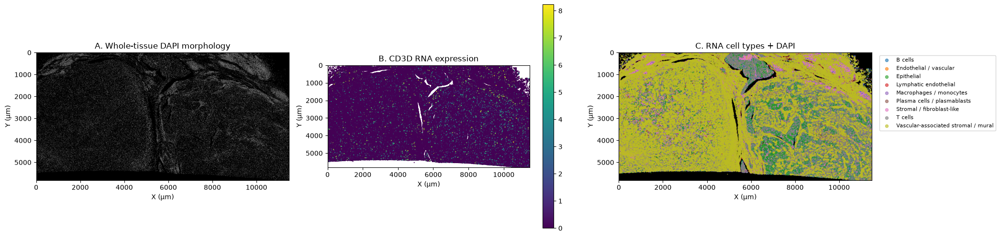

In [91]:
#Visualize morphology cell-type marker overlay
from scipy.sparse import issparse

# ----------------------------------------
# 1. Cell coordinates and annotations
# ----------------------------------------

coords = adata_clust.obsm["spatial"]
labels = (
    adata_clust.obs["cell_type"]
    .astype("object")
    .fillna("Unassigned")
    .astype(str)
    .to_numpy()
)
# Use ALL cells
print("Total cells:", len(coords))

# ----------------------------------------
# 2. Full DAPI image dimensions
# ----------------------------------------

pixel_size = 0.2125  # µm/pixel at original resolution

# If dapi_full was loaded from a lower-resolution pyramid level,
# use its actual effective pixel size instead.
image_height, image_width = dapi_full.shape

x0, y0 = 0, 0

# Assumes the image is aligned with Xenium spatial coordinates
# and starts at (0, 0).
x1 = image_width * pixel_size
y1 = image_height * pixel_size

print("DAPI image dimensions (µm):", x1, y1)

# ----------------------------------------
# 3. Extract CD3D expression for ALL cells
# ----------------------------------------

gene = "CD3D"

expression = adata_clust[:, gene].X

if issparse(expression):
    expression = expression.toarray()

expression = np.asarray(expression).ravel()

# ----------------------------------------
# 4. Plot whole-tissue morphology comparison
# ----------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# A. DAPI morphology
axes[0].imshow(
    dapi_full,
    cmap="gray",
    extent=[x0, x1, y1, y0],
    vmin=np.percentile(dapi_full, 5),
    vmax=np.percentile(dapi_full, 99.5)
)

axes[0].set_title("A. Whole-tissue DAPI morphology")

# B. CD3D RNA expression
im = axes[1].scatter(
    coords[:, 0],
    coords[:, 1],
    c=expression,
    cmap="viridis",
    s=0.3,
    rasterized=True
)

axes[1].set_title(f"B. {gene} RNA expression")

fig.colorbar(
    im,
    ax=axes[1],
    shrink=0.7
)

# C. Cell types over DAPI
axes[2].imshow(
    dapi_full,
    cmap="gray",
    extent=[x0, x1, y1, y0],
    vmin=np.percentile(dapi_full, 5),
    vmax=np.percentile(dapi_full, 99.5)
)

for cell_type in np.unique(labels):

    selected = labels == cell_type

    axes[2].scatter(
        coords[selected, 0],
        coords[selected, 1],
        s=0.3,
        alpha=0.6,
        label=cell_type,
        rasterized=True
    )

axes[2].set_title("C. RNA cell types + DAPI")

axes[2].legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    markerscale=8
)

# ----------------------------------------
# 5. Formatting
# ----------------------------------------

for ax in axes:

    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)

    ax.set_aspect("equal")

    ax.set_xlabel("X (µm)")
    ax.set_ylabel("Y (µm)")

plt.tight_layout()

# ----------------------------------------
# 6. Save figure
# ----------------------------------------

plt.savefig(
    "/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/"
    "STATE_analyses/Xenium_DAPI_RNA_morphology_validation_full.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Compute spatially varying genes

In [92]:
import squidpy as sq
# Build the spatial neighborg graph

# Check coordinates
print(adata.obsm["spatial"].shape)

# Build spatial neighbors
sq.gr.spatial_neighbors(
    adata,
    spatial_key="spatial",
    coord_type="generic",
    n_neighs=6
)

/mnt/home/plazarod/.conda/envs/xenium_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/mnt/home/plazarod/.conda/envs/xenium_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


(465534, 2)
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_2247795/2213068033.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


In [96]:
X = adata.X

values = X.data if sparse.issparse(X) else X.ravel()

print("Min:", values.min())
print("Max:", values.max())
print("Mean:", values.mean())
print("First 20 values:", values[:20])

Min: 1.0
Max: 752.0
Mean: 2.9982898
First 20 values: [1. 1. 6. 1. 2. 1. 2. 1. 1. 1. 3. 1. 3. 1. 2. 2. 1. 2. 5. 1.]


In [97]:
#Normalize count data
# Preserve raw counts
adata.layers["counts"] = adata.X.copy()

# Normalize and log-transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

/tmp/ipykernel_2247795/293240918.py:6: UserWarning: Some cells have zero counts
  sc.pp.normalize_total(adata, target_sum=1e4)


In [115]:
X = adata.X

values = X.data if sparse.issparse(X) else X.ravel()

print("First 20 values:", values[:20])
print("Min:", values.min())
print("Max:", values.max())
print("Mean:", values.mean())


print("NaN values:", np.isnan(values).sum())
print("Infinite values:", np.isinf(values).sum())
print("Genes requested:", len(values))
#print("Genes returned:", len(values.uns["moranI"]))

First 20 values: [4.9003243 4.9003243 6.685861  4.9003243 5.5897427 4.9003243 5.5897427
 4.9003243 4.9003243 4.9003243 5.9939613 4.9003243 5.9939613 4.9003243
 5.5897427 5.5897427 4.9003243 5.5897427 6.503789  4.9003243]
Min: 1.4665935
Max: 9.210441
Mean: 5.0781283
NaN values: 0
Infinite values: 0
Genes requested: 16473705


In [116]:
import inspect
print(inspect.signature(sq.gr.spatial_autocorr))

(adata: 'AnnData | SpatialData', connectivity_key: 'str' = 'spatial_connectivities', genes: 'str | int | Sequence[str] | Sequence[int] | None' = None, mode: "SpatialAutocorr | Literal['moran', 'geary']" = 'moran', transformation: 'bool' = True, n_perms: 'int | None' = None, two_tailed: 'bool' = False, corr_method: 'str | None' = 'fdr_bh', attr: "Literal['obs', 'X', 'obsm']" = 'X', layer: 'str | None' = None, seed: 'int | None' = None, use_raw: 'bool' = False, copy: 'bool' = False, n_jobs: 'int | None' = None, backend: 'str' = 'loky', show_progress_bar: 'bool' = True, *, table_key: 'str | None' = None) -> 'pd.DataFrame | None'


In [117]:
#Calculates Moran's I spatial autocoorelation

# Compute Moran's I

sq.gr.spatial_autocorr(
    adata,
    mode="moran",
    genes=genes,
    n_perms=100,
    n_jobs=4,
    
)

print("Moran's I results:", adata.uns["moranI"].shape)

  0%|          | 0/100 [00:00<?, ?/s]

/mnt/home/plazarod/.conda/envs/xenium_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/mnt/home/plazarod/.conda/envs/xenium_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/mnt/home/plazarod/.conda/envs/xenium_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/mnt/home/plazarod/.conda/envs/xenium_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/mnt/home/plazarod/.conda/envs/xenium_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__d

Moran's I results: (404, 9)


In [119]:
print("Stored Moran's I results:", adata.uns["moranI"].shape)
print("Current svg:", svg.shape)
print("Significant svg:", svg_sig.shape)

print("Stored columns:", adata.uns["moranI"].columns.tolist())

Stored Moran's I results: (404, 9)
Current svg: (2, 9)
Significant svg: (2, 9)
Stored columns: ['I', 'pval_norm', 'var_norm', 'pval_z_sim', 'pval_sim', 'var_sim', 'pval_norm_fdr_bh', 'pval_z_sim_fdr_bh', 'pval_sim_fdr_bh']


In [121]:
##retrieve SVGs
# Retrieve all 404 genes
svg = adata.uns["moranI"].copy()

# Sort by Moran's I
svg = svg.sort_values("I", ascending=False)

display(svg.head(20))

,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
MS4A1,0.566473,0.0,6.626000e-07,0.0,0.009901,1.298418e-06,0.0,0.0,0.01023
CXCL6,0.479779,0.0,6.626000e-07,0.0,0.009901,1.141523e-06,0.0,0.0,0.01023
MET,0.371817,0.0,6.626000e-07,0.0,0.009901,1.161438e-06,0.0,0.0,0.01023
MZB1,0.365657,0.0,6.626000e-07,0.0,0.009901,1.055970e-06,0.0,0.0,0.01023
CXCL10,0.363589,0.0,6.626000e-07,0.0,0.009901,8.702848e-07,0.0,0.0,0.01023
CD79A,0.347733,0.0,6.626000e-07,0.0,0.009901,8.304600e-07,0.0,0.0,0.01023
FCGR3A,0.330220,0.0,6.626000e-07,0.0,0.009901,7.134428e-07,0.0,0.0,0.01023
BANK1,0.322594,0.0,6.626000e-07,0.0,0.009901,1.033392e-06,0.0,0.0,0.01023
CXCL9,0.309269,0.0,6.626000e-07,0.0,0.009901,8.105566e-07,0.0,0.0,0.01023
TNC,0.288333,0.0,6.626000e-07,0.0,0.009901,8.956057e-07,0.0,0.0,0.01023


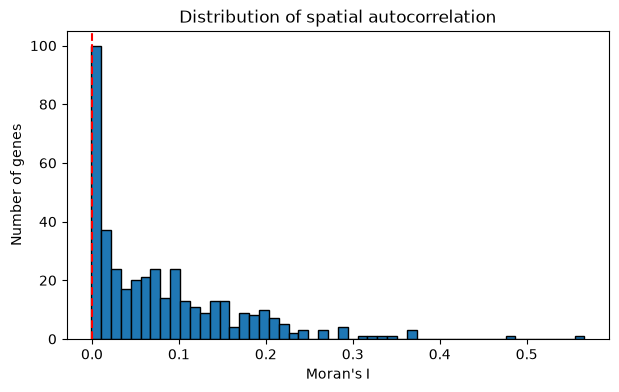

In [123]:

##Examine distribution of Moran's I accross genes
plt.figure(figsize=(7, 4))
plt.hist(svg["I"], bins=50, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Moran's I")
plt.ylabel("Number of genes")
plt.title("Distribution of spatial autocorrelation")
plt.show()



In [125]:
# Sort by Moran's I
svg = svg.sort_values("I", ascending=False)

# Identify significant spatially variable genes
svg_sig = svg[
    (svg["pval_sim_fdr_bh"] < 0.05) &
    (svg["I"] > 0)
].copy()

print(f"Genes tested: {len(svg)}")
print(f"Significant SVGs: {len(svg_sig)}")

display(svg_sig.head(20))

# Save results
svg_sig.to_csv(
    "/mnt/research/HFHMSU-Pancreas/AlmaP_Project_data/Xenium_significant_SVGs.csv"
)

Genes tested: 404
Significant SVGs: 397


,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
MS4A1,0.566473,0.0,6.626000e-07,0.0,0.009901,1.298418e-06,0.0,0.0,0.01023
CXCL6,0.479779,0.0,6.626000e-07,0.0,0.009901,1.141523e-06,0.0,0.0,0.01023
MET,0.371817,0.0,6.626000e-07,0.0,0.009901,1.161438e-06,0.0,0.0,0.01023
MZB1,0.365657,0.0,6.626000e-07,0.0,0.009901,1.055970e-06,0.0,0.0,0.01023
CXCL10,0.363589,0.0,6.626000e-07,0.0,0.009901,8.702848e-07,0.0,0.0,0.01023
CD79A,0.347733,0.0,6.626000e-07,0.0,0.009901,8.304600e-07,0.0,0.0,0.01023
FCGR3A,0.330220,0.0,6.626000e-07,0.0,0.009901,7.134428e-07,0.0,0.0,0.01023
BANK1,0.322594,0.0,6.626000e-07,0.0,0.009901,1.033392e-06,0.0,0.0,0.01023
CXCL9,0.309269,0.0,6.626000e-07,0.0,0.009901,8.105566e-07,0.0,0.0,0.01023
TNC,0.288333,0.0,6.626000e-07,0.0,0.009901,8.956057e-07,0.0,0.0,0.01023


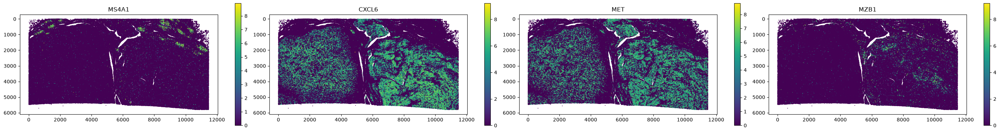

In [126]:
top_genes = svg_sig.head(4).index.tolist()

fig, axes = plt.subplots(
    1, len(top_genes),
    figsize=(7 * len(top_genes), 5),
    constrained_layout=True,
    squeeze=False
)

axes = axes.ravel()
coords = adata.obsm["spatial"]

for ax, gene in zip(axes, top_genes):

    expression = adata[:, gene].X
    expression = np.asarray(
        expression.toarray() if hasattr(expression, "toarray")
        else expression
    ).ravel()

    scatter = ax.scatter(
        coords[:, 0],
        coords[:, 1],
        c=expression,
        cmap="viridis",
        s=0.2,
        rasterized=True
    )

    ax.set_title(gene)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    fig.colorbar(scatter, ax=ax, shrink=0.7)

plt.show()

# Over-representation analysis

In [127]:
import gseapy as gp
# Significant spatially variable genes
svg_genes = svg_sig.index.tolist()

# Background: all genes tested for Moran's I
background = svg.index.tolist()

print("SVGs:", len(svg_genes))
print("Background genes:", len(background))

SVGs: 397
Background genes: 404


In [144]:
# Run pathway enrichment
hallmark_sets = gp.read_gmt(
    "/mnt/home/plazarod/Documents/bioinf_scripts/h.all.v2024.1.Hs.symbols.gmt"
)
canonical_pathways = gp.read_gmt(
    "/mnt/home/plazarod/Documents/bioinf_scripts/c2.cp.v2026.1.Hs.symbols.gmt"
)


# Combine both collections
all_gene_sets = {**hallmark_sets, **canonical_pathways}

enr = gp.enrichr(
    gene_list=svg_genes,
    gene_sets=all_gene_sets,
    background=background,
    organism="human",
    outdir=None
)

display(enr.results.sort_values("Adjusted P-value").head(20))

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes
0,gs_ind_0,BIOCARTA_41BB_PATHWAY,1/1,0.982673,0.999937,0.056747,0.000992,TNFRSF9
1,gs_ind_0,BIOCARTA_ACE2_PATHWAY,1/1,0.982673,0.999937,0.056747,0.000992,ACE2
2,gs_ind_0,BIOCARTA_AGR_PATHWAY,1/1,0.982673,0.999937,0.056747,0.000992,EGFR
3,gs_ind_0,BIOCARTA_AHSP_PATHWAY,2/2,0.965605,0.999937,0.094817,0.003319,AHSP;ALAS2
4,gs_ind_0,BIOCARTA_AKAP95_PATHWAY,1/1,0.982673,0.999937,0.056747,0.000992,CDK1
5,gs_ind_0,BIOCARTA_AKAPCENTROSOME_PATHWAY,1/1,0.982673,0.999937,0.056747,0.000992,CDK1
6,gs_ind_0,BIOCARTA_ALK_PATHWAY,2/2,0.965605,0.999937,0.094817,0.003319,MEF2C;CTNNB1
7,gs_ind_0,BIOCARTA_ALTERNATIVE_PATHWAY,2/2,0.965605,0.999937,0.094817,0.003319,CFB;C7
8,gs_ind_0,BIOCARTA_AMI_PATHWAY,2/2,0.965605,0.999937,0.094817,0.003319,TFPI;AHSP
9,gs_ind_0,BIOCARTA_ARENRF2_PATHWAY,1/1,0.982673,0.999937,0.056747,0.000992,FXYD2


In [145]:
print("Pathways tested:", len(enr.results))

display(
    enr.results[
        ["Term", "Overlap", "P-value", "Adjusted P-value"]
    ].sort_values("Adjusted P-value").head(15)
)

Pathways tested: 2101


,Term,Overlap,P-value,Adjusted P-value
0,BIOCARTA_41BB_PATHWAY,1/1,0.982673,0.999937
1,BIOCARTA_ACE2_PATHWAY,1/1,0.982673,0.999937
2,BIOCARTA_AGR_PATHWAY,1/1,0.982673,0.999937
3,BIOCARTA_AHSP_PATHWAY,2/2,0.965605,0.999937
4,BIOCARTA_AKAP95_PATHWAY,1/1,0.982673,0.999937
5,BIOCARTA_AKAPCENTROSOME_PATHWAY,1/1,0.982673,0.999937
6,BIOCARTA_ALK_PATHWAY,2/2,0.965605,0.999937
7,BIOCARTA_ALTERNATIVE_PATHWAY,2/2,0.965605,0.999937
8,BIOCARTA_AMI_PATHWAY,2/2,0.965605,0.999937
9,BIOCARTA_ARENRF2_PATHWAY,1/1,0.982673,0.999937


<Axes: title={'center': 'Pathway enrichment of spatially variable genes'}, xlabel='Combined Score'>

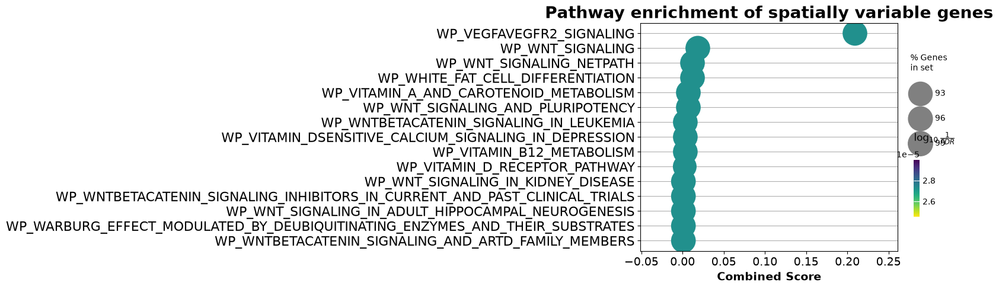

In [149]:
# Plot enriched pathways
from gseapy import dotplot

dotplot(
    enr.results,
    column="Adjusted P-value",
    x="Combined Score",
    cutoff=1,
    top_term=15,
    figsize=(7, 5),
    title="Pathway enrichment of spatially variable genes"
)

# Focus on tumor-immune interactions for pathway enrichment

In [150]:
immune_keywords = [
    "INTERFERON",
    "ANTIGEN_PRESENTATION",
    "MHC",
    "T_CELL",
    "TCR",
    "PD_1",
    "PD1",
    "CTLA4",
    "CHECKPOINT",
    "CYTOKINE",
    "CHEMOKINE",
    "TNF",
    "NFKB",
    "INTERLEUKIN",
    "INFLAMMATORY",
    "IMMUNE",
    "TGF_BETA",
    "CYTOTOXIC"
]

immune_sets = {
    name: genes
    for name, genes in all_gene_sets.items()
    if any(keyword in name.upper() for keyword in immune_keywords)
}

print(f"Selected {len(immune_sets)} immune-related pathways")
print(list(immune_sets)[:20])

Selected 227 immune-related pathways
['HALLMARK_G2M_CHECKPOINT', 'HALLMARK_INFLAMMATORY_RESPONSE', 'HALLMARK_INTERFERON_ALPHA_RESPONSE', 'HALLMARK_INTERFERON_GAMMA_RESPONSE', 'HALLMARK_TGF_BETA_SIGNALING', 'HALLMARK_TNFA_SIGNALING_VIA_NFKB', 'SA_MMP_CYTOKINE_CONNECTION', 'BIOCARTA_CTLA4_PATHWAY', 'BIOCARTA_CYTOKINE_PATHWAY', 'BIOCARTA_EPONFKB_PATHWAY', 'BIOCARTA_MHC_PATHWAY', 'BIOCARTA_NFKB_PATHWAY', 'BIOCARTA_TCRA_PATHWAY', 'BIOCARTA_TCR_PATHWAY', 'BIOCARTA_TCYTOTOXIC_PATHWAY', 'BIOCARTA_TNFR1_PATHWAY', 'BIOCARTA_TNFR2_PATHWAY', 'KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY', 'KEGG_AUTOIMMUNE_THYROID_DISEASE', 'KEGG_CHEMOKINE_SIGNALING_PATHWAY']


In [152]:
enr_immune = gp.enrichr(
    gene_list=svg_genes,
    gene_sets=immune_sets,
    background=background,
    organism="human",
    outdir=None
)

display(
    enr_immune.results.sort_values("P-value")[
        ["Term", "Overlap", "P-value", "Adjusted P-value"]
    ].head(20)
)

,Term,Overlap,P-value,Adjusted P-value
59,REACTOME_INNATE_IMMUNE_SYSTEM,52/52,0.378229,0.982673
35,REACTOME_ADAPTIVE_IMMUNE_SYSTEM,50/50,0.393666,0.982673
44,REACTOME_CYTOKINE_SIGNALING_IN_IMMUNE_SYSTEM,46/46,0.426165,0.982673
84,REACTOME_SIGNALING_BY_INTERLEUKINS,30/30,0.580230,0.982673
14,KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION,28/28,0.602484,0.982673
6,HALLMARK_INFLAMMATORY_RESPONSE,26/26,0.625465,0.982673
98,WP_CYTOKINECYTOKINE_RECEPTOR_INTERACTION,23/23,0.661344,0.982673
83,REACTOME_REGULATION_OF_T_CELL_ACTIVATION_BY_CD...,17/17,0.738422,0.982673
10,HALLMARK_TNFA_SIGNALING_VIA_NFKB,16/16,0.751989,0.982673
8,HALLMARK_INTERFERON_GAMMA_RESPONSE,15/15,0.765769,0.982673


<Axes: title={'center': 'RCC Tumor–Immune Pathway Enrichment'}, xlabel='Combined Score'>

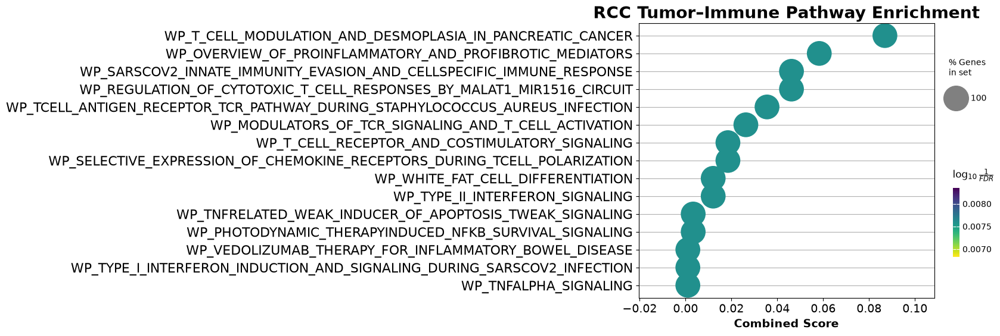

In [154]:


dotplot(
    enr_immune.results,
    column="Adjusted P-value",
    x="Combined Score",
    cutoff=1,
    top_term=15,
    figsize=(8, 6),
    title="RCC Tumor–Immune Pathway Enrichment"
)

# Spatial neighborhgood analysis

In [156]:
print(adata_clust.obs.columns.tolist())

['x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'n_genes_by_counts', 'nucleus_cell_ratio', 'nucleus_only_flag', 'transcript_density', 'tissue_region', 'n_genes', 'leiden', 'cell_type', 'cell_type_previous']


In [157]:
print(adata_clust.obs["cell_type"].value_counts())
print(adata_clust.obsp.keys())

cell_type
B cells                                124873
Vascular-associated stromal / mural     97473
Macrophages / monocytes                 65311
Epithelial                              64414
T cells                                 45058
Stromal / fibroblast-like               27869
Plasma cells / plasmablasts             18263
Lymphatic endothelial                   13802
Endothelial / vascular                   2796
Name: count, dtype: int64
KeysView(PairwiseArrays with keys: 'distances', 'connectivities')


In [158]:
# Construct the spatial graph
import squidpy as sq

sq.gr.spatial_neighbors(
    adata_clust,
    spatial_key="spatial",
    coord_type="generic",
    n_neighs=6
)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_2247795/3599479811.py:4: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


In [161]:
# Calculate the neighborghood enrichment
adata_clust.obs["cell_type"] = adata_clust.obs["cell_type"].astype("category")
sq.gr.nhood_enrichment(
    adata_clust,
    cluster_key="cell_type",
    n_perms=100,
    n_jobs=1,
    numba_parallel=False
)

  0%|          | 0/100 [00:00<?, ?/s]

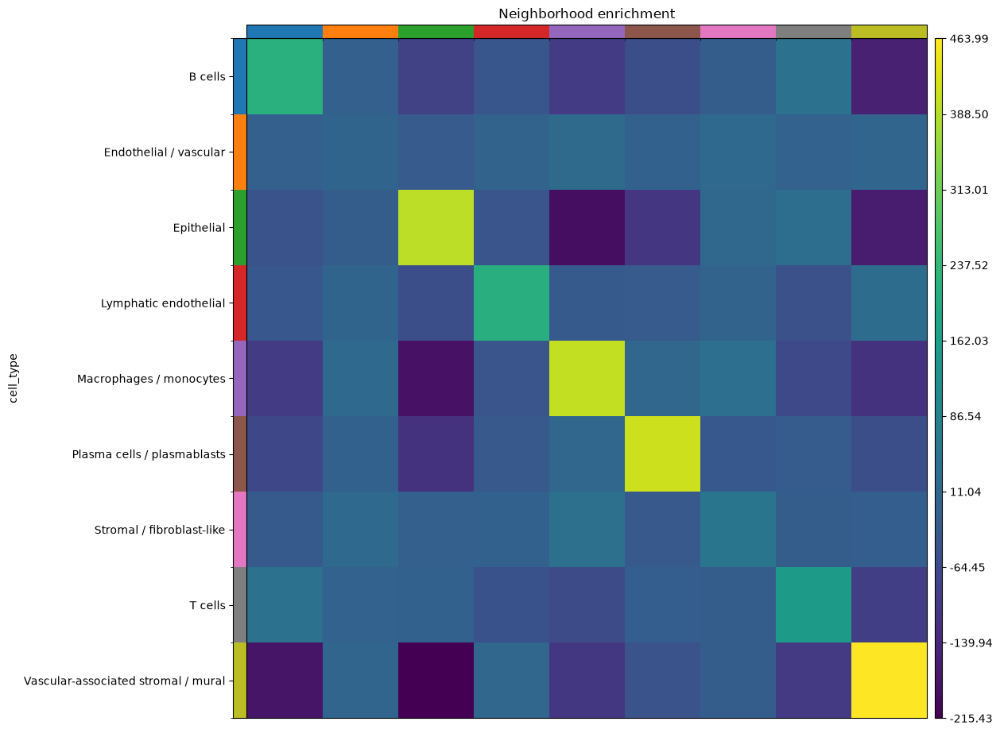

In [162]:
# Plot the enrichment matrix
sq.pl.nhood_enrichment(
    adata_clust,
    cluster_key="cell_type",
    figsize=(9, 9)
)

In [163]:


result = adata_clust.uns["cell_type_nhood_enrichment"]

z = pd.DataFrame(
    result["zscore"],
    index=adata_clust.obs["cell_type"].cat.categories,
    columns=adata_clust.obs["cell_type"].cat.categories
)

display(
    z.loc[
        "Epithelial",
        ["T cells", "Macrophages / monocytes",
         "B cells", "Plasma cells / plasmablasts"]
    ]
)

T cells                         29.630565
Macrophages / monocytes       -191.194377
B cells                        -42.051940
Plasma cells / plasmablasts   -107.983959
Name: Epithelial, dtype: float64

## T cells positively enriched near epithelial cells

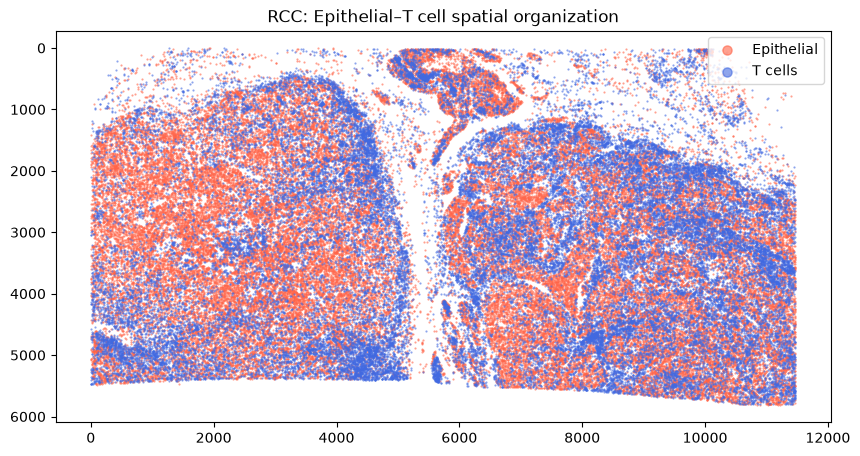

In [164]:


subset = adata_clust[
    adata_clust.obs["cell_type"].isin(["Epithelial", "T cells"])
]

coords = subset.obsm["spatial"]
labels = subset.obs["cell_type"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 9))

for cell_type, color in [
    ("Epithelial", "tomato"),
    ("T cells", "royalblue")
]:
    mask = labels == cell_type
    ax.scatter(
        coords[mask, 0],
        coords[mask, 1],
        s=0.3,
        c=color,
        label=cell_type,
        alpha=0.6,
        rasterized=True
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.legend(markerscale=12)
ax.set_title("RCC: Epithelial–T cell spatial organization")
plt.show()

## Epithelial–T-cell plot shows substantial spatial intermingling, with regional differences in their distributions.

# Results summary



### Quality control

The Xenium dataset contained **465,534 cells** and **77.1 million transcript records**, with all 405 genes in the targeted panel represented in the expression matrix. Cells contained a median of 70 transcripts and 32 detected genes. Transcript-level quality assessment showed that 81.7% of transcript records had quality scores ≥Q20, while 78.5% of high-confidence gene transcripts were assigned to cells. Segmentation QC identified 2.41% of cells with multiple nuclei and 0.39% with nucleus-to-cell area ratios of 1, suggesting potential segmentation artifacts in a small subset of cells. Spatial QC also revealed regional variation in transcript density.

### Cell-type identification and spatial organization

After filtering cells with fewer than five detected genes, **459,859 cells** were retained for secondary analysis. Leiden clustering (resolution 0.5), differential marker expression, and canonical marker evaluation identified nine annotated cell populations, including epithelial, T, B, plasma, macrophage/monocyte, stromal, and endothelial populations.

Spatial autocorrelation analysis using Moran's I identified **397 significant spatially variable genes among 404 tested** (permutation-based FDR < 0.05), indicating substantial spatial structure in gene expression.

Pathway overrepresentation analysis using Hallmark and canonical pathway gene sets did not identify statistically significant enrichment after multiple-testing correction. A focused analysis of tumor–immune pathways, including cytokine signaling, interferon responses, and T-cell activation, was also nonsignificant.

Spatial neighborhood enrichment revealed distinct epithelial–immune associations. T cells were enriched among epithelial neighbors (Z = 29.63), whereas macrophages/monocytes (Z = −191.19), B cells (Z = −42.05), and plasma cells/plasmablasts (Z = −107.98) were depleted relative to randomized cell-type distributions. Spatial visualization showed epithelial–T-cell intermingling with regional heterogeneity, suggesting nonuniform immune organization within the tissue.

## Limitations

Several limitations should be considered. First, the targeted 405-gene Xenium panel restricts transcriptome-wide characterization, pathway coverage, and cell-type resolution. In particular, epithelial annotations do not independently distinguish malignant from nonmalignant cells.

Second, the large proportion of genes identified as spatially variable (397/404) limits the discriminatory power of pathway overrepresentation analysis. The nonsignificant enrichment results should therefore not be interpreted as evidence that the corresponding biological pathways are inactive.

Third, neighborhood enrichment measures spatial association rather than direct cell–cell communication. The large sample size, tissue architecture, and underlying cell-type distributions may contribute to the magnitude of the observed Z-scores. Additional region-specific analyses and histological validation would be required to establish whether these patterns reflect tumor infiltration, immune exclusion, or other tissue compartmentalization.

Finally, the analysis represents a single tissue specimen, limiting generalizability across RCC patients and histological subtypes.

# Reproducibility

In [28]:
# Reproducibility: computational environment

import sys
import os
import platform
import importlib.metadata as md


print("Python:", sys.version.split()[0])
print("Conda environment:", os.environ.get("CONDA_DEFAULT_ENV", "Not detected"))
print("Operating system:", platform.platform())

packages = [
    "numpy",
    "pandas",
    "scanpy",
    "anndata",
    "squidpy",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "gseapy",
    "tifffile",
    "opencv-python-headless",
    "SimpleITK",
    "ipympl"
]

versions = []

for package in packages:
    try:
        version = md.version(package)
    except md.PackageNotFoundError:
        version = "Not installed"

    versions.append({
        "Package": package,
        "Version": version
    })

environment_df = pd.DataFrame(versions)
display(environment_df)

Python: 3.12.15
Conda environment: xenium_spatial
Operating system: Linux-5.15.0-187-generic-x86_64-with-glibc2.35


,Package,Version
0,numpy,2.5.3
1,pandas,3.0.6
2,scanpy,1.12.4
3,anndata,0.13.4
4,squidpy,1.8.2
5,scipy,1.18.1
6,scikit-learn,1.9.1
7,matplotlib,3.11.2
8,seaborn,0.13.2
9,gseapy,1.3.1


In [29]:
!conda env export --no-builds > xenium_spatial_environment.yml

### Computational environment and reproducibility

All analyses were performed in Python using the `xenium_spatial` conda environment on the Michigan State University ICER computing cluster.

The workflow used Scanpy and AnnData for single-cell RNA analysis, Squidpy for spatial statistics and neighborhood enrichment, GSEApy for pathway enrichment, and SimpleITK/OpenCV for H&E–Xenium image registration.

The complete software environment is documented in `xenium_spatial_environment.yml`, with additional Python package versions recorded in `xenium_requirements.txt`.